# Smart Electricity Consumption Optimizer — Tasks 7 and 8
Run Task 7, then continue to Task 8 below in this same notebook. Task 8 reads the saved models directly; no ZIP transfer is needed.
Task 7 training runs only when you run its cells. If those cells have already completed in this runtime, continue from the Task 8 handoff cell.
The Task 7 implementation is preserved. Task 8 adds SHAP, activation heatmaps and model comparisons.


In [1]:
# -*- coding: utf-8 -*-

# Task 7 — Smart Electricity Consumption Optimizer
## FINAL Phase: peak-gated multi-task LSTM for one-hour-ahead power forecasting

This is the final improvement phase.

**Goal:** predict mean household `Global_active_power` (kW) for the 15-minute
interval ending **one hour after the forecast origin**.

The previous V2 already used all real electrical measurements and improved the
test result to approximately:

- MAE = 0.4131 kW
- RMSE = 0.6107 kW
- R² = 0.4143
- High-demand RMSE = 1.6916 kW

The remaining weakness was clear: **rare high-demand events**.

This final version therefore keeps the leakage-safe multivariate pipeline and
adds three targeted improvements:

1. **Ramp / trend / rolling-maximum features** so the network can detect demand
   that is beginning to rise.
2. A **multi-task LSTM** that learns two tasks together:
   - future power regression,
   - probability that the future target is a high-demand event.
3. A **peak-gated regression head**. The model learns a normal forecast plus a
   positive peak adjustment, and the learned peak probability controls how much
   of that adjustment is applied.

High-demand training examples receive more weight, but model selection still
uses **validation data only**. The final test period is not used for tuning.

No occupancy, weather, tariff, or appliance-state values are fabricated.
Only real UCI electrical measurements, past-derived statistics, and known
calendar information are used.

In [2]:
# Install only missing dependencies into this notebook's active environment.
import importlib.util
import subprocess
import sys

dependencies = {
    "tensorflow": "tensorflow==2.20.0",
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.2,<3",
    "sklearn": "scikit-learn>=1.5,<2",
    "matplotlib": "matplotlib>=3.8,<4",
    "joblib": "joblib>=1.4,<2",
}
missing = [spec for module, spec in dependencies.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

## 1. Configuration and final experimental design

The complete dataset is split chronologically:

- 70% training
- 15% validation
- 15% final test

The default final comparison trains:

- `basic_mlp` — non-recurrent comparison,
- `lstm_mv_compact` — V2-style multivariate LSTM,
- `lstm_final_peak_gate` — final multi-task peak-gated LSTM.

The final LSTM is **not automatically assumed to be better**. LSTM candidates
are selected using a validation score that is 75% overall forecasting quality
and 25% high-demand forecasting quality, both normalized against persistence.

This is appropriate for an electricity optimizer because normal accuracy
matters, but peak periods are operationally important.

`EXTENDED_SEARCH=True` optionally adds one wider peak-gated model. Keep it
`False` initially because this final notebook already trains the main final
architecture.

In [3]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import hashlib
import json
import platform
import shutil
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42

RUN_MODE = "full"                 # "full" for final results; "smoke" only checks pipeline
EXTENDED_SEARCH = False           # optional wider peak-gated LSTM

SEQUENCE_LENGTH = 96              # previous 24 h at 15-minute resolution
HORIZON = 4                       # forecast target ends 60 minutes after origin
BATCH_SIZE = 256
MAX_FORWARD_FILL = 4              # at most 1 hour of past-only filling
MAX_EPOCHS = 60 if RUN_MODE == "full" else 2

TRAIN_FRACTION = 0.70
VALIDATION_END_FRACTION = 0.85

# Peak definition is learned from TRAINING targets only.
PEAK_QUANTILE = 0.90

# Training emphasis for the final multi-task model.
PEAK_REGRESSION_WEIGHT = 2.5
PEAK_CLASSIFICATION_WEIGHT = 4.0
AUXILIARY_PEAK_LOSS_WEIGHT = 0.20

# Validation model-selection objective:
# 75% overall normalized RMSE + 25% high-demand normalized RMSE.
VALIDATION_OVERALL_WEIGHT = 0.75
VALIDATION_PEAK_WEIGHT = 0.25

ELECTRICAL_FEATURES = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]
TARGET_FEATURE = "Global_active_power"

assert RUN_MODE in {"full", "smoke"}
assert abs(VALIDATION_OVERALL_WEIGHT + VALIDATION_PEAK_WEIGHT - 1.0) < 1e-9

keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass

try:
    tf.config.threading.set_intra_op_parallelism_threads(
        min(8, os.cpu_count() or 2)
    )
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass

ROOT = Path.cwd()
DATA_DIR = ROOT / "task7_data"
DATA_DIR.mkdir(exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = ROOT / "task7_FINAL_outputs" / f"{RUN_MODE}_{RUN_ID}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print("Run mode:", RUN_MODE)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Artifacts:", OUTPUT_DIR)

if RUN_MODE == "smoke":
    print("SMOKE TEST ONLY — do not report these metrics as final results.")

Run mode: full
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Artifacts: /content/task7_FINAL_outputs/full_20261012T061006_195817Z


## 2. Load and audit the complete original dataset

Source: UCI **Individual Household Electric Power Consumption** dataset
(2,075,259 minute-level records, December 2006–November 2010).

Unlike Version 1, this notebook reads all seven real electrical measurements:
active power, reactive power, voltage, current, and the three sub-metering
signals.

No external occupancy or weather values are fabricated. Missing/invalid
measurements are retained as missing at this stage and handled causally in
the interval preprocessing step.

In [4]:
SOURCE_URL = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual%2Bhousehold%2Belectric%2Bpower%2Bconsumption.zip"
)
ARCHIVE = DATA_DIR / "household_power_consumption.zip"
EXPECTED_RAW_ROWS = 2_075_259

if not ARCHIVE.exists():
    temporary_archive = ARCHIVE.with_suffix(".download")
    request = urllib.request.Request(
        SOURCE_URL,
        headers={"User-Agent": "Task7-Electricity-Project/2.0"}
    )
    with urllib.request.urlopen(request, timeout=180) as response, temporary_archive.open("wb") as dest:
        shutil.copyfileobj(response, dest)
    if not zipfile.is_zipfile(temporary_archive):
        raise ValueError("Download was not a valid ZIP archive; check the UCI source URL.")
    temporary_archive.replace(ARCHIVE)

usecols = ["Date", "Time", *ELECTRICAL_FEATURES]

with zipfile.ZipFile(ARCHIVE) as archive:
    with archive.open("household_power_consumption.txt") as member:
        raw = pd.read_csv(
            member,
            sep=";",
            usecols=usecols,
            na_values=["?"],
            low_memory=False
        )

assert len(raw) == EXPECTED_RAW_ROWS, (
    f"Expected the full UCI data ({EXPECTED_RAW_ROWS:,} rows), got {len(raw):,}."
)

raw["Datetime"] = pd.to_datetime(
    raw["Date"] + " " + raw["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

for feature in ELECTRICAL_FEATURES:
    raw[feature] = pd.to_numeric(raw[feature], errors="coerce")
    invalid = (~np.isfinite(raw[feature])) | (raw[feature] < 0)
    raw.loc[invalid, feature] = np.nan

invalid_times = int(raw["Datetime"].isna().sum())
duplicate_times = int(raw["Datetime"].duplicated().sum())

assert invalid_times == 0 and duplicate_times == 0, (
    "Resolve timestamp errors before modeling."
)

raw = raw.sort_values("Datetime").set_index("Datetime")

missing_by_feature = {
    feature: int(raw[feature].isna().sum())
    for feature in ELECTRICAL_FEATURES
}

data_audit = {
    "source_url": SOURCE_URL,
    "archive_sha256": hashlib.sha256(ARCHIVE.read_bytes()).hexdigest(),
    "raw_rows": int(len(raw)),
    "raw_start": str(raw.index.min()),
    "raw_end": str(raw.index.max()),
    "invalid_timestamps": invalid_times,
    "duplicate_timestamps": duplicate_times,
    "missing_or_invalid_rows_by_feature": missing_by_feature,
}

display(pd.Series({
    "raw_rows": data_audit["raw_rows"],
    "raw_start": data_audit["raw_start"],
    "raw_end": data_audit["raw_end"],
    "invalid_timestamps": invalid_times,
    "duplicate_timestamps": duplicate_times,
}))
display(pd.Series(missing_by_feature, name="Missing/invalid minute readings"))

,0
raw_rows,2075259
raw_start,2006-12-16 17:24:00
raw_end,2010-11-26 21:02:00
invalid_timestamps,0
duplicate_timestamps,0


,Missing/invalid minute readings
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


## 3. Causal multivariate preprocessing

Each 15-minute value is the mean of a **completed** interval. For each
electrical feature, an interval is considered genuinely observed only when
all 15 minute readings are valid.

For model **inputs**, an incomplete interval may be forward-filled for at
most four 15-minute bins (one hour), using past values only. Longer gaps
remain missing and any history window containing them is excluded.

The model also receives an `electrical_observed_fraction` value at every time
step, telling it what fraction of the seven electrical signals were genuinely
observed rather than filled.

The **target is never imputed**: `Global_active_power` at the future target
interval must be fully observed.

This preserves the same forecasting semantics as Version 1 while giving the
LSTM richer real-world electrical context.

,0
interval_rows,138352
fully_observed_target_intervals,136551
forward_filled_target_input_intervals,113
unfilled_target_input_intervals,1688


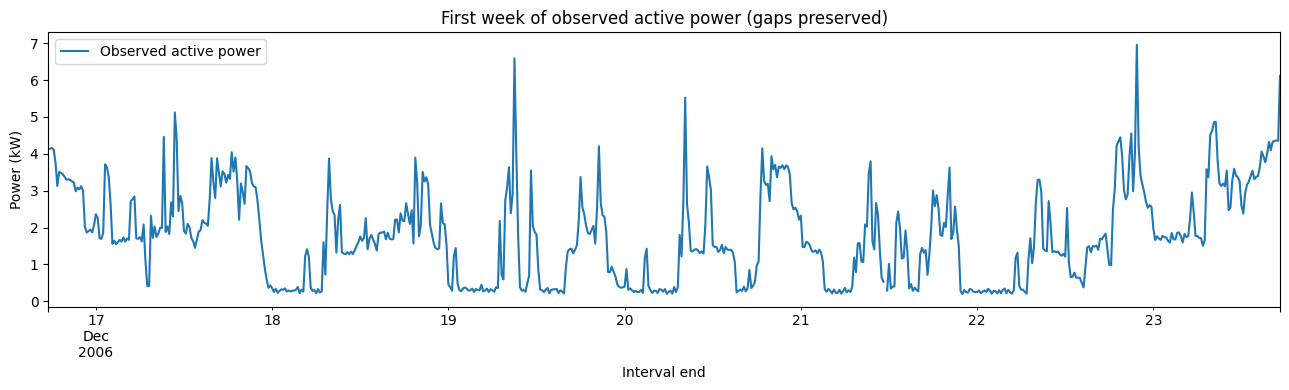

In [5]:
def prepare_multivariate(minute_frame, features, max_forward_fill=4):
    if not minute_frame.index.is_unique or not minute_frame.index.is_monotonic_increasing:
        raise ValueError("Minute readings must have unique, sorted timestamps.")

    minute_frame = minute_frame[features].copy()

    bins = minute_frame.resample("15min", closed="left", label="right")
    means = bins.mean()
    counts = bins.count()

    observed = counts.eq(15)
    actual = means.where(observed)
    input_values = actual.ffill(limit=max_forward_fill)

    out = pd.DataFrame(index=means.index)

    for feature in features:
        out[f"actual_{feature}"] = actual[feature]
        out[f"input_{feature}"] = input_values[feature]
        out[f"observed_{feature}"] = observed[feature].astype(float)

    # Convenient aliases used by the target/context/evaluation code.
    out["actual_kw"] = out[f"actual_{TARGET_FEATURE}"]
    out["input_kw"] = out[f"input_{TARGET_FEATURE}"]
    out["observed"] = out[f"observed_{TARGET_FEATURE}"].astype(bool)

    # One compact data-quality signal for the LSTM history.
    out["electrical_observed_fraction"] = observed[features].mean(axis=1).astype(float)

    return out

power = prepare_multivariate(
    raw,
    ELECTRICAL_FEATURES,
    MAX_FORWARD_FILL
)

data_audit.update({
    "interval_rows": int(len(power)),
    "fully_observed_target_intervals": int(power["observed"].sum()),
    "forward_filled_target_input_intervals": int(
        (power["actual_kw"].isna() & power["input_kw"].notna()).sum()
    ),
    "unfilled_target_input_intervals": int(power["input_kw"].isna().sum()),
})

display(pd.Series({
    "interval_rows": data_audit["interval_rows"],
    "fully_observed_target_intervals": data_audit["fully_observed_target_intervals"],
    "forward_filled_target_input_intervals": data_audit["forward_filled_target_input_intervals"],
    "unfilled_target_input_intervals": data_audit["unfilled_target_input_intervals"],
}))

fig, ax = plt.subplots(figsize=(13, 4))
power["actual_kw"].iloc[:7 * 96].plot(ax=ax, label="Observed active power")
ax.set(
    title="First week of observed active power (gaps preserved)",
    xlabel="Interval end",
    ylabel="Power (kW)"
)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "data_first_week.png", dpi=150)
plt.show()

## 4. Final feature set and chronological partitions

The history branch still receives 96 previous 15-minute intervals (24 hours)
of real electrical measurements and cyclical calendar information.

The final phase strengthens the **context branch** with features aimed at
detecting a developing peak.

### Short-term ramps
Examples:

- change in active power over 15 minutes,
- change over 30 minutes,
- change over 1 hour,
- change in current (`Global_intensity`) over 15 minutes and 1 hour.

These tell the model whether electricity demand is **rising**, not only what
its current level is.

### Rolling behaviour

For active power:

- rolling mean over 30 min, 1 h, 2 h, 4 h, 24 h,
- rolling standard deviation over 1 h, 4 h, 24 h,
- rolling maximum over 1 h, 4 h, 24 h,
- rolling minimum and range over 1 h and 4 h.

For current and sub-metering:

- latest value,
- short-term mean,
- short-term maximum,
- short-term ramp.

### Seasonal lags

The model receives the corresponding target slot from:

- yesterday,
- two days ago,
- one week ago.

All meter-derived features use information available **at or before the
forecast origin**. Future calendar information is allowed because the future
clock/day/month is already known.

In [6]:
def calendar_features(index):
    hour = index.hour + index.minute / 60.0

    return pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * hour / 24),
        "hour_cos": np.cos(2 * np.pi * hour / 24),

        "dow_sin": np.sin(2 * np.pi * index.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * index.dayofweek / 7),

        "month_sin": np.sin(2 * np.pi * (index.month - 1) / 12),
        "month_cos": np.cos(2 * np.pi * (index.month - 1) / 12),

        "weekend": (index.dayofweek >= 5).astype(float),
    }, index=index)


def build_context(power_frame, horizon=4):
    p = power_frame["input_kw"]

    # At target row t, p.shift(horizon) is the LAST value known at
    # forecast origin t-horizon.
    latest = p.shift(horizon)
    lag_15m = p.shift(horizon + 1)
    lag_30m = p.shift(horizon + 2)
    lag_1h = p.shift(horizon + 4)
    lag_2h = p.shift(horizon + 8)

    frame = pd.DataFrame(index=power_frame.index)

    # ----------------------------------------------------------
    # Level / lag features
    # ----------------------------------------------------------
    frame["latest_kw"] = latest
    frame["15min_before_origin_kw"] = lag_15m
    frame["30min_before_origin_kw"] = lag_30m
    frame["one_hour_before_origin_kw"] = lag_1h
    frame["two_hours_before_origin_kw"] = lag_2h

    # ----------------------------------------------------------
    # Ramps: positive means load has risen.
    # ----------------------------------------------------------
    frame["ramp_15min_kw"] = latest - lag_15m
    frame["ramp_30min_kw"] = latest - lag_30m
    frame["ramp_1hour_kw"] = latest - lag_1h
    frame["ramp_2hour_kw"] = latest - lag_2h

    # ----------------------------------------------------------
    # Seasonal target-slot lags.
    # These values happened well before the current forecast.
    # ----------------------------------------------------------
    frame["target_slot_previous_day_kw"] = p.shift(96)
    frame["target_slot_two_days_ago_kw"] = p.shift(192)
    frame["target_slot_previous_week_kw"] = p.shift(672)

    # ----------------------------------------------------------
    # Rolling active-power summaries ending at forecast origin.
    # ----------------------------------------------------------
    windows = {
        "30min": 2,
        "1hour": 4,
        "2hours": 8,
        "4hours": 16,
        "24hours": 96,
    }

    for name, window in windows.items():
        rolling = p.rolling(window)

        frame[f"mean_previous_{name}_kw"] = (
            rolling.mean().shift(horizon)
        )

        if window >= 4:
            frame[f"std_previous_{name}_kw"] = (
                rolling.std(ddof=0).shift(horizon)
            )

        frame[f"max_previous_{name}_kw"] = (
            rolling.max().shift(horizon)
        )

        if window <= 16:
            frame[f"min_previous_{name}_kw"] = (
                rolling.min().shift(horizon)
            )
            frame[f"range_previous_{name}_kw"] = (
                frame[f"max_previous_{name}_kw"]
                - frame[f"min_previous_{name}_kw"]
            )

    frame["observed_fraction_previous_day"] = (
        power_frame["electrical_observed_fraction"]
        .rolling(96)
        .mean()
        .shift(horizon)
    )

    # ----------------------------------------------------------
    # Other electrical signals.
    # ----------------------------------------------------------
    for feature in ELECTRICAL_FEATURES[1:]:
        series = power_frame[f"input_{feature}"]
        frame[f"latest_{feature}"] = series.shift(horizon)

    intensity = power_frame["input_Global_intensity"]

    frame["intensity_15min_before_origin"] = (
        intensity.shift(horizon + 1)
    )
    frame["intensity_1hour_before_origin"] = (
        intensity.shift(horizon + 4)
    )

    frame["ramp_15min_Global_intensity"] = (
        intensity.shift(horizon)
        - intensity.shift(horizon + 1)
    )
    frame["ramp_1hour_Global_intensity"] = (
        intensity.shift(horizon)
        - intensity.shift(horizon + 4)
    )

    frame["mean_previous_hour_Global_intensity"] = (
        intensity.rolling(4).mean().shift(horizon)
    )
    frame["max_previous_4hours_Global_intensity"] = (
        intensity.rolling(16).max().shift(horizon)
    )

    # ----------------------------------------------------------
    # Aggregate sub-metering activity.
    # ----------------------------------------------------------
    submeter_total = (
        power_frame["input_Sub_metering_1"]
        + power_frame["input_Sub_metering_2"]
        + power_frame["input_Sub_metering_3"]
    )

    frame["latest_submeter_total"] = (
        submeter_total.shift(horizon)
    )
    frame["submeter_total_15min_before_origin"] = (
        submeter_total.shift(horizon + 1)
    )
    frame["ramp_15min_submeter_total"] = (
        submeter_total.shift(horizon)
        - submeter_total.shift(horizon + 1)
    )
    frame["mean_previous_hour_submeter_total"] = (
        submeter_total.rolling(4).mean().shift(horizon)
    )
    frame["max_previous_4hours_submeter_total"] = (
        submeter_total.rolling(16).max().shift(horizon)
    )

    # Target calendar features are known in advance.
    frame = frame.join(
        calendar_features(frame.index).add_prefix("target_")
    )

    return frame


context = build_context(power, HORIZON)
CONTEXT_FEATURES = context.columns.tolist()

n = len(power)
train_end = int(n * TRAIN_FRACTION)
val_end = int(n * VALIDATION_END_FRACTION)

HISTORY_INPUT_COLUMNS = [
    f"input_{feature}"
    for feature in ELECTRICAL_FEATURES
]


def valid_target_indices(
    power_frame,
    context_frame,
    sequence_length=96,
    horizon=4
):
    targets = np.arange(
        len(power_frame),
        dtype=np.int64
    )

    ends = targets - horizon + 1
    starts = ends - sequence_length

    row_missing = (
        power_frame[HISTORY_INPUT_COLUMNS]
        .isna()
        .any(axis=1)
        .to_numpy()
        .astype(np.int64)
    )

    cumulative = np.r_[
        0,
        np.cumsum(row_missing)
    ]

    bounds_ok = starts >= 0

    safe_start = np.maximum(starts, 0)
    safe_end = np.maximum(ends, 0)

    window_ok = (
        cumulative[safe_end]
        - cumulative[safe_start]
    ) == 0

    context_ok = np.isfinite(
        context_frame.to_numpy()
    ).all(axis=1)

    # The target itself must be genuinely measured.
    target_ok = power_frame[
        "observed"
    ].to_numpy()

    eligible = (
        bounds_ok
        & window_ok
        & context_ok
        & target_ok
    )

    return targets[eligible]


all_indices = valid_target_indices(
    power,
    context,
    SEQUENCE_LENGTH,
    HORIZON
)

split_indices = {
    "train": all_indices[
        all_indices < train_end
    ],

    "validation": all_indices[
        (all_indices >= train_end + HORIZON)
        & (all_indices < val_end)
    ],

    "test": all_indices[
        all_indices >= val_end + HORIZON
    ],
}

full_split_counts = {
    name: int(len(ids))
    for name, ids in split_indices.items()
}

if RUN_MODE == "smoke":
    for name, cap in [
        ("train", 2048),
        ("validation", 512),
        ("test", 512),
    ]:
        ids = split_indices[name]

        split_indices[name] = ids[
            np.linspace(
                0,
                len(ids) - 1,
                min(cap, len(ids)),
                dtype=int
            )
        ]

train_indices, val_indices, test_indices = (
    split_indices[k]
    for k in (
        "train",
        "validation",
        "test",
    )
)

assert all(
    len(ids) > 0
    for ids in split_indices.values()
)

assert train_indices[-1] < val_indices[0] - HORIZON
assert val_indices[-1] < test_indices[0] - HORIZON

split_table = pd.DataFrame([
    {
        "Split": name,
        "Eligible_samples_full":
            full_split_counts[name],
        "Used_samples":
            len(ids),
        "First_target":
            power.index[ids[0]],
        "Last_target":
            power.index[ids[-1]],
        "First_forecast_origin":
            power.index[ids[0] - HORIZON],
    }
    for name, ids in split_indices.items()
])

display(split_table)

print(
    "Context feature count:",
    len(CONTEXT_FEATURES)
)

split_table.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False
)

,Split,Eligible_samples_full,Used_samples,First_target,Last_target,First_forecast_origin
0,train,94302,94302,2006-12-23 17:45:00,2009-09-20 12:45:00,2006-12-23 16:45:00
1,validation,19672,19672,2009-09-20 14:00:00,2010-04-24 17:00:00,2009-09-20 13:00:00
2,test,18703,18703,2010-04-24 18:15:00,2010-11-26 21:00:00,2010-04-24 17:15:00


Context feature count: 59


## 5. Scaling, peak labels, and training batches

Every electrical signal is standardized using **training data only**.
The context scaler is also fitted using training examples only.

A target is labelled as a high-demand event when its active power is above
the **training 90th percentile**.

The final multi-task model receives two learning signals:

### Regression
Predict future power.

Peak targets receive `2.5×` regression sample weight so a large miss during a
rare high-load event matters more during training.

### Peak classification
Predict whether the future target is above the training peak threshold.

Peak targets receive `4×` classification weight to fight the roughly 90/10
class imbalance.

Validation and test metrics are always reported **without these weights**.
The weights affect learning only.

In [7]:
# ============================================================
# FIT ELECTRICAL SCALERS USING TRAINING DATA ONLY
# ============================================================

electrical_scalers = {}
scaled_history_columns = []

for feature in ELECTRICAL_FEATURES:

    scaler = StandardScaler()

    train_observed = (
        power[f"actual_{feature}"]
        .iloc[:train_end]
        .dropna()
        .to_numpy()
        .reshape(-1, 1)
    )

    scaler.fit(train_observed)

    electrical_scalers[
        feature
    ] = scaler

    transformed = scaler.transform(
        power[
            [f"input_{feature}"]
        ].to_numpy()
    ).ravel()

    scaled_history_columns.append(
        transformed
    )


power_scaler = electrical_scalers[
    TARGET_FEATURE
]

context_scaler = StandardScaler().fit(
    context.iloc[train_indices]
)

calendar = calendar_features(
    power.index
)

HISTORY_FEATURES = [
    *(
        f"{feature}_scaled"
        for feature in ELECTRICAL_FEATURES
    ),
    "electrical_observed_fraction",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
]

history_values = np.column_stack([
    *scaled_history_columns,

    power[
        "electrical_observed_fraction"
    ].to_numpy(dtype=float),

    calendar[
        [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
        ]
    ].to_numpy(),
]).astype(np.float32)


context_values = context_scaler.transform(
    context
).astype(np.float32)


target_scaled = power_scaler.transform(
    power[["actual_kw"]].to_numpy()
).astype(np.float32)


# ============================================================
# TRAINING-ONLY PEAK DEFINITION
# ============================================================

peak_threshold = float(
    power["actual_kw"]
    .iloc[:train_end]
    .dropna()
    .quantile(PEAK_QUANTILE)
)

peak_labels = (
    power["actual_kw"].to_numpy()
    >= peak_threshold
).astype(np.float32)


regression_sample_weights = np.where(
    peak_labels > 0.5,
    PEAK_REGRESSION_WEIGHT,
    1.0,
).astype(np.float32)


classification_sample_weights = np.where(
    peak_labels > 0.5,
    PEAK_CLASSIFICATION_WEIGHT,
    1.0,
).astype(np.float32)


print(
    "History feature count:",
    len(HISTORY_FEATURES)
)

print(
    "Context feature count:",
    len(CONTEXT_FEATURES)
)

print(
    f"Training {PEAK_QUANTILE:.0%} peak threshold:",
    round(peak_threshold, 4),
    "kW"
)

print(
    "Training peak target fraction:",
    round(
        float(
            peak_labels[
                train_indices
            ].mean()
        ),
        4
    )
)


# ============================================================
# CONSTANT TENSORS
# ============================================================

history_tensor = tf.constant(
    history_values
)

context_tensor = tf.constant(
    context_values
)

target_tensor = tf.constant(
    target_scaled
)

peak_label_tensor = tf.constant(
    peak_labels.reshape(-1, 1)
)

regression_weight_tensor = tf.constant(
    regression_sample_weights
)

classification_weight_tensor = tf.constant(
    classification_sample_weights
)

window_offsets = tf.range(
    SEQUENCE_LENGTH,
    dtype=tf.int64
)


# ============================================================
# DIRECT NUMPY INPUTS FOR SMALL PROBES / SAVING
# ============================================================

def inputs_for_indices(ids):

    ids = np.asarray(
        ids,
        dtype=np.int64
    )

    window_ids = (
        ids[:, None]
        - HORIZON
        - SEQUENCE_LENGTH
        + 1
        + np.arange(SEQUENCE_LENGTH)
    )

    return {
        "history":
            history_values[window_ids],

        "context":
            context_values[ids],
    }


# ============================================================
# FEATURE-ONLY DATASET FOR PREDICTION
# ============================================================

def make_feature_dataset(
    ids,
    training=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        np.asarray(
            ids,
            dtype=np.int64
        )
    )

    if training:

        dataset = dataset.shuffle(
            min(len(ids), 8192),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    def gather_features(batch_ids):

        positions = (
            batch_ids[:, None]
            - HORIZON
            - SEQUENCE_LENGTH
            + 1
            + window_offsets[None, :]
        )

        return {
            "history":
                tf.gather(
                    history_tensor,
                    positions
                ),

            "context":
                tf.gather(
                    context_tensor,
                    batch_ids
                ),
        }

    dataset = dataset.map(
        gather_features,
        num_parallel_calls=2,
        deterministic=True
    )

    options = tf.data.Options()
    options.threading.private_threadpool_size = 2

    return (
        dataset
        .with_options(options)
        .prefetch(1)
    )


# ============================================================
# REGRESSION-ONLY DATASET
# ============================================================

def make_regression_dataset(
    ids,
    training=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        np.asarray(
            ids,
            dtype=np.int64
        )
    )

    if training:

        dataset = dataset.shuffle(
            min(len(ids), 8192),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    def gather(batch_ids):

        positions = (
            batch_ids[:, None]
            - HORIZON
            - SEQUENCE_LENGTH
            + 1
            + window_offsets[None, :]
        )

        features = {
            "history":
                tf.gather(
                    history_tensor,
                    positions
                ),

            "context":
                tf.gather(
                    context_tensor,
                    batch_ids
                ),
        }

        target = tf.gather(
            target_tensor,
            batch_ids
        )

        return features, target

    return (
        dataset
        .map(
            gather,
            num_parallel_calls=2,
            deterministic=True
        )
        .prefetch(1)
    )


# ============================================================
# MULTI-TASK DATASET
# ============================================================

def make_multitask_dataset(
    ids,
    training=False,
    apply_training_weights=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        np.asarray(
            ids,
            dtype=np.int64
        )
    )

    if training:

        dataset = dataset.shuffle(
            min(len(ids), 8192),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    def gather(batch_ids):

        positions = (
            batch_ids[:, None]
            - HORIZON
            - SEQUENCE_LENGTH
            + 1
            + window_offsets[None, :]
        )

        features = {
            "history":
                tf.gather(
                    history_tensor,
                    positions
                ),

            "context":
                tf.gather(
                    context_tensor,
                    batch_ids
                ),
        }

        targets = {
            "forecast_scaled":
                tf.gather(
                    target_tensor,
                    batch_ids
                ),

            "peak_probability":
                tf.gather(
                    peak_label_tensor,
                    batch_ids
                ),
        }

        if not apply_training_weights:
            return features, targets

        weights = {
            "forecast_scaled":
                tf.gather(
                    regression_weight_tensor,
                    batch_ids
                ),

            "peak_probability":
                tf.gather(
                    classification_weight_tensor,
                    batch_ids
                ),
        }

        return (
            features,
            targets,
            weights
        )

    return (
        dataset
        .map(
            gather,
            num_parallel_calls=2,
            deterministic=True
        )
        .prefetch(1)
    )


# ============================================================
# SANITY CHECK
# ============================================================

for features, targets in make_regression_dataset(
    train_indices
).take(1):

    assert tuple(
        features["history"].shape[1:]
    ) == (
        SEQUENCE_LENGTH,
        len(HISTORY_FEATURES)
    )

    assert np.isfinite(
        features["history"].numpy()
    ).all()

    assert np.isfinite(
        features["context"].numpy()
    ).all()

    assert np.isfinite(
        targets.numpy()
    ).all()

    print(
        "History batch:",
        features["history"].shape,
        "| Context batch:",
        features["context"].shape
    )

History feature count: 12
Context feature count: 59
Training 90% peak threshold: 2.5031 kW
Training peak target fraction: 0.0992
History batch: (256, 96, 12) | Context batch: (256, 59)


## 6. FINAL architecture — peak-gated multi-task LSTM

The final architecture explicitly models the problem discovered in V2.

### Shared temporal representation

```text
96 × multivariate history
        ↓
LSTM 64
        ↓
Dropout
        ↓
LSTM 32
        ↓
Context features
        ↓
Dense shared representation
```

### Two learning tasks

The shared representation produces:

1. **Peak probability**
   - “Is the target one hour ahead likely to be high demand?”

2. **Power forecast**
   - a normal/base forecast,
   - a learned positive peak adjustment.

The final forecast is conceptually:

```text
final forecast
=
base forecast
+
peak probability × peak adjustment
```

So when the classifier sees little evidence of a peak, the peak correction is
small. When it sees strong evidence, the model can raise its forecast.

The regression loss is **Huber loss**, which is more robust to extremely large
errors than pure MSE while still learning from them. Peak examples are also
up-weighted.

The peak-classification loss is an auxiliary binary cross-entropy objective.
It shapes the same LSTM representation but does not replace the regression
target.

In [8]:
# ============================================================
# MODEL BUILDERS
# ============================================================

def build_regression_model(
    kind,
    name,
    units=(32, 16),
    dropout=0.15,
    l2_strength=1e-5,
    learning_rate=1e-3,
):

    history_input = keras.Input(
        (
            SEQUENCE_LENGTH,
            len(HISTORY_FEATURES)
        ),
        name="history"
    )

    context_input = keras.Input(
        (
            len(CONTEXT_FEATURES),
        ),
        name="context"
    )

    penalty = regularizers.l2(
        l2_strength
    )

    if kind == "lstm":

        h = layers.LSTM(
            units[0],
            return_sequences=True,
            kernel_regularizer=penalty,
            name="lstm_temporal_features"
        )(history_input)

        h = layers.Dropout(
            dropout,
            name="sequence_dropout"
        )(h)

        h = layers.LSTM(
            units[1],
            return_sequences=False,
            kernel_regularizer=penalty,
            name="lstm_summary"
        )(h)

        h = layers.Dropout(
            dropout,
            name="summary_dropout"
        )(h)

    else:

        h = layers.Flatten(
            name="flatten_history"
        )(history_input)

    h = layers.Concatenate(
        name="history_and_context"
    )([
        h,
        context_input
    ])

    h = layers.Dense(
        64 if kind == "mlp" else 32,
        activation="relu",
        kernel_regularizer=penalty,
        name="dense_features"
    )(h)

    h = layers.Dropout(
        dropout
    )(h)

    if kind == "mlp":

        h = layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=penalty
        )(h)

    output = layers.Dense(
        1,
        name="forecast_scaled"
    )(h)

    network = keras.Model(
        inputs={
            "history": history_input,
            "context": context_input,
        },
        outputs=output,
        name=name,
    )

    network.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0,
        ),
        loss="mse",
        metrics=[
            keras.metrics.MeanSquaredError(
                name="mse"
            ),
            keras.metrics.MeanAbsoluteError(
                name="mae"
            ),
        ],
    )

    return network


def build_peak_gate_model(
    name="lstm_final_peak_gate",
    units=(64, 32),
    dropout=0.20,
    l2_strength=1e-4,
    learning_rate=5e-4,
):

    history_input = keras.Input(
        (
            SEQUENCE_LENGTH,
            len(HISTORY_FEATURES)
        ),
        name="history"
    )

    context_input = keras.Input(
        (
            len(CONTEXT_FEATURES),
        ),
        name="context"
    )

    penalty = regularizers.l2(
        l2_strength
    )

    # --------------------------------------------------------
    # Temporal representation
    # --------------------------------------------------------
    h = layers.LSTM(
        units[0],
        return_sequences=True,
        kernel_regularizer=penalty,
        name="lstm_temporal_features"
    )(history_input)

    h = layers.Dropout(
        dropout,
        name="sequence_dropout"
    )(h)

    h = layers.LSTM(
        units[1],
        return_sequences=False,
        kernel_regularizer=penalty,
        name="lstm_summary"
    )(h)

    h = layers.Dropout(
        dropout,
        name="summary_dropout"
    )(h)

    # --------------------------------------------------------
    # Combine temporal and engineered context
    # --------------------------------------------------------
    shared = layers.Concatenate(
        name="history_and_context"
    )([
        h,
        context_input
    ])

    shared = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=penalty,
        name="shared_dense"
    )(shared)

    shared = layers.Dropout(
        0.15,
        name="shared_dropout"
    )(shared)

    shared = layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=penalty,
        name="shared_dense_2"
    )(shared)

    # --------------------------------------------------------
    # Auxiliary task: probability of high demand
    # --------------------------------------------------------
    peak_probability = layers.Dense(
        1,
        activation="sigmoid",
        name="peak_probability"
    )(shared)

    # --------------------------------------------------------
    # Regression:
    # normal/base forecast + gated positive peak adjustment
    # --------------------------------------------------------
    base_forecast = layers.Dense(
        1,
        name="base_forecast_scaled"
    )(shared)

    peak_adjustment = layers.Dense(
        1,
        activation="softplus",
        name="peak_adjustment_scaled"
    )(shared)

    gated_adjustment = layers.Multiply(
        name="gated_peak_adjustment"
    )([
        peak_probability,
        peak_adjustment
    ])

    forecast = layers.Add(
        name="forecast_scaled"
    )([
        base_forecast,
        gated_adjustment
    ])

    network = keras.Model(
        inputs={
            "history": history_input,
            "context": context_input,
        },
        outputs={
            "forecast_scaled":
                forecast,

            "peak_probability":
                peak_probability,
        },
        name=name,
    )

    network.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0,
        ),

        loss={
            "forecast_scaled":
                keras.losses.Huber(
                    delta=1.0
                ),

            "peak_probability":
                keras.losses.BinaryCrossentropy(),
        },

        loss_weights={
            "forecast_scaled":
                1.0,

            "peak_probability":
                AUXILIARY_PEAK_LOSS_WEIGHT,
        },

        metrics={
            "forecast_scaled": [
                keras.metrics.MeanSquaredError(
                    name="mse"
                ),
                keras.metrics.MeanAbsoluteError(
                    name="mae"
                ),
            ],

            "peak_probability": [
                keras.metrics.AUC(
                    name="auc"
                ),
                keras.metrics.Precision(
                    name="precision"
                ),
                keras.metrics.Recall(
                    name="recall"
                ),
            ],
        },
    )

    return network


# ============================================================
# METRICS / PREDICTION HELPERS
# ============================================================

def regression_metrics(
    actual,
    prediction
):

    actual = np.asarray(
        actual
    ).ravel()

    prediction = np.asarray(
        prediction
    ).ravel()

    assert (
        len(actual)
        == len(prediction)
    )

    assert np.isfinite(
        actual
    ).all()

    assert np.isfinite(
        prediction
    ).all()

    mse = mean_squared_error(
        actual,
        prediction
    )

    return {
        "MAE_kW":
            float(
                mean_absolute_error(
                    actual,
                    prediction
                )
            ),

        "MSE_kW2":
            float(mse),

        "RMSE_kW":
            float(np.sqrt(mse)),

        "R2":
            float(
                r2_score(
                    actual,
                    prediction
                )
            ),
    }


def prediction_outputs(
    network,
    ids
):

    outputs = network.predict(
        make_feature_dataset(ids),
        verbose=0
    )

    peak_probability = None

    if isinstance(
        outputs,
        dict
    ):

        scaled = outputs[
            "forecast_scaled"
        ]

        peak_probability = outputs[
            "peak_probability"
        ].ravel()

    elif isinstance(
        outputs,
        (list, tuple)
    ):

        # Safe fallback if a Keras version returns a list.
        name_to_output = dict(
            zip(
                network.output_names,
                outputs
            )
        )

        scaled = name_to_output[
            "forecast_scaled"
        ]

        if (
            "peak_probability"
            in name_to_output
        ):
            peak_probability = (
                name_to_output[
                    "peak_probability"
                ]
                .ravel()
            )

    else:

        scaled = outputs

    raw_prediction = (
        power_scaler
        .inverse_transform(
            np.asarray(
                scaled
            ).reshape(-1, 1)
        )
        .ravel()
    )

    clipped_fraction = float(
        np.mean(
            raw_prediction < 0
        )
    )

    prediction_kw = np.maximum(
        raw_prediction,
        0.0
    )

    return (
        prediction_kw,
        peak_probability,
        clipped_fraction,
    )


# ============================================================
# BUILD CANDIDATES
# ============================================================

candidate_specs = [
    {
        "name":
            "basic_mlp",

        "kind":
            "mlp",

        "multitask":
            False,

        "builder":
            lambda: build_regression_model(
                kind="mlp",
                name="basic_mlp",
                dropout=0.20,
                l2_strength=1e-4,
                learning_rate=1e-3,
            ),
    },

    {
        "name":
            "lstm_mv_compact",

        "kind":
            "lstm",

        "multitask":
            False,

        "builder":
            lambda: build_regression_model(
                kind="lstm",
                name="lstm_mv_compact",
                units=(32, 16),
                dropout=0.15,
                l2_strength=1e-5,
                learning_rate=1e-3,
            ),
    },

    {
        "name":
            "lstm_final_peak_gate",

        "kind":
            "lstm",

        "multitask":
            True,

        "builder":
            lambda: build_peak_gate_model(
                name="lstm_final_peak_gate",
                units=(64, 32),
                dropout=0.20,
                l2_strength=1e-4,
                learning_rate=5e-4,
            ),
    },
]


if EXTENDED_SEARCH:

    candidate_specs.append({
        "name":
            "lstm_final_peak_gate_wide",

        "kind":
            "lstm",

        "multitask":
            True,

        "builder":
            lambda: build_peak_gate_model(
                name="lstm_final_peak_gate_wide",
                units=(96, 48),
                dropout=0.25,
                l2_strength=2e-4,
                learning_rate=3e-4,
            ),
    })


# ============================================================
# VALIDATION BASELINES
# ============================================================

actual_val = (
    power["actual_kw"]
    .iloc[val_indices]
    .to_numpy()
)

peak_val_mask = (
    actual_val
    >= peak_threshold
)

BASELINE_COLUMNS = {
    "Persistence":
        "latest_kw",

    "Daily seasonal":
        "target_slot_previous_day_kw",

    "Weekly seasonal":
        "target_slot_previous_week_kw",
}

validation_predictions = {
    name:
        context[column]
        .iloc[val_indices]
        .to_numpy()

    for name, column
    in BASELINE_COLUMNS.items()
}

persistence_val_metrics = regression_metrics(
    actual_val,
    validation_predictions[
        "Persistence"
    ]
)

persistence_val_peak_metrics = regression_metrics(
    actual_val[
        peak_val_mask
    ],
    validation_predictions[
        "Persistence"
    ][
        peak_val_mask
    ]
)


# ============================================================
# TRAIN ALL FINAL CANDIDATES
# ============================================================

histories = {}
trained_paths = {}
validation_peak_probabilities = {}
fit_records = []

for spec in candidate_specs:

    keras.backend.clear_session()
    keras.utils.set_random_seed(
        SEED
    )

    network = spec[
        "builder"
    ]()

    network.summary()

    if spec["multitask"]:

        monitor_metric = (
            "val_forecast_scaled_mse"
        )

        train_ds = make_multitask_dataset(
            train_indices,
            training=True,
            apply_training_weights=True
        )

        validation_ds = make_multitask_dataset(
            val_indices,
            training=False,
            apply_training_weights=False
        )

    else:

        monitor_metric = "val_mse"

        train_ds = make_regression_dataset(
            train_indices,
            training=True
        )

        validation_ds = make_regression_dataset(
            val_indices,
            training=False
        )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor=monitor_metric,
            patience=8,
            min_delta=1e-5,
            restore_best_weights=True,
            mode="min",
            verbose=1,
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor=monitor_metric,
            factor=0.5,
            patience=3,
            min_lr=1e-5,
            mode="min",
            verbose=1,
        ),

        keras.callbacks.TerminateOnNaN(),
    ]

    started = time.perf_counter()

    fitted = network.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=2,
    )

    elapsed = (
        time.perf_counter()
        - started
    )

    history_frame = pd.DataFrame(
        fitted.history
    )

    history_frame.index = np.arange(
        1,
        len(history_frame) + 1
    )

    history_frame.index.name = "Epoch"

    history_frame.to_csv(
        OUTPUT_DIR
        / f"{spec['name']}_history.csv"
    )

    histories[
        spec["name"]
    ] = history_frame

    path = (
        OUTPUT_DIR
        / f"{spec['name']}.keras"
    )

    network.save(
        path
    )

    trained_paths[
        spec["name"]
    ] = path

    (
        val_prediction,
        val_peak_probability,
        clipped_fraction,
    ) = prediction_outputs(
        network,
        val_indices
    )

    validation_predictions[
        spec["name"]
    ] = val_prediction

    validation_peak_probabilities[
        spec["name"]
    ] = val_peak_probability

    overall_metrics = regression_metrics(
        actual_val,
        val_prediction
    )

    peak_metrics = regression_metrics(
        actual_val[
            peak_val_mask
        ],
        val_prediction[
            peak_val_mask
        ]
    )

    # Normalize against persistence so overall and peak RMSE
    # are on comparable relative scales.
    normalized_overall = (
        overall_metrics[
            "RMSE_kW"
        ]
        / persistence_val_metrics[
            "RMSE_kW"
        ]
    )

    normalized_peak = (
        peak_metrics[
            "RMSE_kW"
        ]
        / persistence_val_peak_metrics[
            "RMSE_kW"
        ]
    )

    validation_objective = (
        VALIDATION_OVERALL_WEIGHT
        * normalized_overall
        +
        VALIDATION_PEAK_WEIGHT
        * normalized_peak
    )

    record = {
        "Model":
            spec["name"],

        "Kind":
            spec["kind"],

        "Multitask_peak_gate":
            spec["multitask"],

        **overall_metrics,

        "Peak_MAE_kW":
            peak_metrics[
                "MAE_kW"
            ],

        "Peak_RMSE_kW":
            peak_metrics[
                "RMSE_kW"
            ],

        "Peak_R2":
            peak_metrics[
                "R2"
            ],

        "Normalized_overall_RMSE_vs_persistence":
            normalized_overall,

        "Normalized_peak_RMSE_vs_persistence":
            normalized_peak,

        "Validation_objective":
            validation_objective,

        "Epochs":
            len(
                history_frame
            ),

        "Parameters":
            int(
                network.count_params()
            ),

        "Training_seconds":
            elapsed,

        "Clipped_fraction":
            clipped_fraction,
    }

    if val_peak_probability is not None:

        val_peak_labels = (
            peak_val_mask
            .astype(int)
        )

        record[
            "Peak_classifier_AUC"
        ] = float(
            roc_auc_score(
                val_peak_labels,
                val_peak_probability
            )
        )

    fit_records.append(
        record
    )

    del network


# ============================================================
# VALIDATION TABLE + FINAL LSTM SELECTION
# ============================================================

validation_results = (
    pd.DataFrame(
        fit_records
    )
    .sort_values(
        "Validation_objective"
    )
)

lstm_validation_rows = (
    validation_results[
        validation_results[
            "Kind"
        ].eq("lstm")
    ]
)

selected_lstm_name = (
    lstm_validation_rows
    .iloc[0][
        "Model"
    ]
)

validation_results.to_csv(
    OUTPUT_DIR
    / "validation_model_comparison.csv",
    index=False
)

display(
    validation_results.round(4)
)

print(
    "FINAL LSTM selected using validation-only objective:",
    selected_lstm_name
)

Model: "basic_mlp"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 96, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_history     │ (None, 1152)      │          0 │ history[0][0]     │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context             │ (None, 59)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ history_and_context │ (None, 1211)      │          0 │ flatten_history[… │
│ (Concatenate)       │                   │            │ context[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 64)        │     77,568 │ history_and_cont… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_scaled     │ (None, 1)         │         33 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 79,681 (311.25 KB)

 Trainable params: 79,681 (311.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
369/369 - 8s - 22ms/step - loss: 0.5875 - mae: 0.5260 - mse: 0.5709 - val_loss: 0.5237 - val_mae: 0.4947 - val_mse: 0.5069 - learning_rate: 0.0010
Epoch 2/60
369/369 - 3s - 7ms/step - loss: 0.5152 - mae: 0.4806 - mse: 0.4982 - val_loss: 0.5100 - val_mae: 0.4799 - val_mse: 0.4930 - learning_rate: 0.0010
Epoch 3/60
369/369 - 3s - 7ms/step - loss: 0.4925 - mae: 0.4681 - mse: 0.4753 - val_loss: 0.5135 - val_mae: 0.4851 - val_mse: 0.4963 - learning_rate: 0.0010
Epoch 4/60
369/369 - 2s - 7ms/step - loss: 0.4802 - mae: 0.4611 - mse: 0.4627 - val_loss: 0.5185 - val_mae: 0.4787 - val_mse: 0.5010 - learning_rate: 0.0010
Epoch 5/60

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
369/369 - 3s - 9ms/step - loss: 0.4710 - mae: 0.4544 - mse: 0.4531 - val_loss: 0.5191 - val_mae: 0.4845 - val_mse: 0.5011 - learning_rate: 0.0010
Epoch 6/60
369/369 - 4s - 11ms/step - loss: 0.4522 - mae: 0.4447 - mse: 0.4341 - val_loss: 0.5146 - val_mae: 0.4845 - val_mse: 0.4965 - l

... (10 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
369/369 - 14s - 37ms/step - forecast_scaled_loss: 0.3889 - forecast_scaled_mae: 0.5610 - forecast_scaled_mse: 0.6253 - loss: 0.5338 - peak_probability_auc: 0.8101 - peak_probability_loss: 0.6189 - peak_probability_precision: 0.3429 - peak_probability_recall: 0.4870 - val_forecast_scaled_loss: 0.2117 - val_forecast_scaled_mae: 0.4894 - val_forecast_scaled_mse: 0.4991 - val_loss: 0.2983 - val_peak_probability_auc: 0.8458 - val_peak_probability_loss: 0.3355 - val_peak_probability_precision: 0.3407 - val_peak_probability_recall: 0.5992 - learning_rate: 5.0000e-04
Epoch 2/60
369/369 - 7s - 20ms/step - forecast_scaled_loss: 0.3387 - forecast_scaled_mae: 0.5021 - forecast_scaled_mse: 0.5317 - loss: 0.4627 - peak_probability_auc: 0.8704 - peak_probability_loss: 0.5285 - peak_probability_precision: 0.3566 - peak_probability_recall: 0.6538 - val_forecast_scaled_loss: 0.2161 - val_forecast_scaled_mae: 0.4888 - val_forecast_scaled_mse: 0.5013 - val_loss: 0.3057 - val_peak_probability_au

,Model,Kind,Multitask_peak_gate,MAE_kW,MSE_kW2,RMSE_kW,R2,Peak_MAE_kW,Peak_RMSE_kW,Peak_R2,Normalized_overall_RMSE_vs_persistence,Normalized_peak_RMSE_vs_persistence,Validation_objective,Epochs,Parameters,Training_seconds,Clipped_fraction,Peak_classifier_AUC
2,lstm_final_peak_gate,lstm,True,0.4854,0.4959,0.7042,0.4856,1.0843,1.3754,-2.1944,0.7504,0.7645,0.7539,12,40195,105.1418,0.0,0.8693
1,lstm_mv_compact,lstm,False,0.4625,0.4808,0.6934,0.5014,1.2807,1.5363,-2.9858,0.7388,0.8540,0.7676,13,11361,82.8936,0.0,NaN
0,basic_mlp,mlp,False,0.4884,0.5143,0.7171,0.4666,1.3839,1.6275,-3.4727,0.7642,0.9046,0.7993,15,79681,48.4305,0.0,NaN


FINAL LSTM selected using validation-only objective: lstm_final_peak_gate


## 7. Freeze selection and evaluate the untouched test period

The LSTM choice is now frozen.

The selected LSTM, the basic MLP, persistence, daily seasonal, and weekly
seasonal forecasts are evaluated on the same final test targets.

No hyperparameter is changed after seeing these test metrics.

For the peak-gated model, the notebook also reports peak-classifier AUC,
precision, recall, and F1. The probability decision threshold is chosen on the
**validation set only** by maximizing validation F1.

In [9]:
# ============================================================
# VALIDATION-ONLY OVERALL COMPARISON
# ============================================================

selection_candidates = [
    "basic_mlp",
    selected_lstm_name,
    *BASELINE_COLUMNS,
]

selected_overall_name = min(
    selection_candidates,
    key=lambda name:
        regression_metrics(
            actual_val,
            validation_predictions[
                name
            ]
        )["RMSE_kW"]
)

selection_record = {
    "selected_lstm":
        selected_lstm_name,

    "selected_overall_on_validation":
        selected_overall_name,

    "lstm_selection_metric":
        (
            f"{VALIDATION_OVERALL_WEIGHT:.2f} * normalized overall RMSE "
            f"+ {VALIDATION_PEAK_WEIGHT:.2f} * normalized peak RMSE"
        ),

    "run_mode":
        RUN_MODE,
}


# ============================================================
# IF THE SELECTED MODEL HAS A PEAK HEAD:
# CHOOSE CLASSIFICATION THRESHOLD ON VALIDATION ONLY
# ============================================================

peak_probability_threshold = None

selected_val_peak_probability = (
    validation_peak_probabilities
    .get(
        selected_lstm_name
    )
)

if selected_val_peak_probability is not None:

    actual_val_peak_label = (
        actual_val
        >= peak_threshold
    ).astype(int)

    thresholds = np.linspace(
        0.05,
        0.95,
        91
    )

    threshold_scores = []

    for threshold in thresholds:

        predicted_label = (
            selected_val_peak_probability
            >= threshold
        ).astype(int)

        threshold_scores.append(
            f1_score(
                actual_val_peak_label,
                predicted_label,
                zero_division=0
            )
        )

    peak_probability_threshold = float(
        thresholds[
            int(
                np.argmax(
                    threshold_scores
                )
            )
        ]
    )

    selection_record[
        "peak_probability_threshold_selected_on_validation"
    ] = (
        peak_probability_threshold
    )


(
    OUTPUT_DIR
    / "selection.json"
).write_text(
    json.dumps(
        selection_record,
        indent=2
    ),
    encoding="utf-8"
)


# ============================================================
# LOAD FROZEN MODELS
# ============================================================

model = keras.models.load_model(
    trained_paths[
        selected_lstm_name
    ]
)

basic_model = keras.models.load_model(
    trained_paths[
        "basic_mlp"
    ]
)


# ============================================================
# FINAL TEST PREDICTIONS
# ============================================================

actual_test = (
    power["actual_kw"]
    .iloc[test_indices]
    .to_numpy()
)

test_predictions = {}
test_clipped = {}
test_peak_probabilities = {}


for name, network in [
    (
        selected_lstm_name,
        model
    ),
    (
        "basic_mlp",
        basic_model
    ),
]:

    (
        prediction,
        peak_probability,
        clipped_fraction,
    ) = prediction_outputs(
        network,
        test_indices
    )

    test_predictions[
        name
    ] = prediction

    test_peak_probabilities[
        name
    ] = peak_probability

    test_clipped[
        name
    ] = clipped_fraction


for name, column in BASELINE_COLUMNS.items():

    test_predictions[
        name
    ] = (
        context[
            column
        ]
        .iloc[
            test_indices
        ]
        .to_numpy()
    )

    test_clipped[
        name
    ] = 0.0


# ============================================================
# REGRESSION METRICS
# ============================================================

test_results = pd.DataFrame([
    {
        "Model":
            name,

        **regression_metrics(
            actual_test,
            prediction
        ),

        "Clipped_fraction":
            test_clipped[
                name
            ],
    }

    for name, prediction
    in test_predictions.items()
])


persistence_rmse = float(
    test_results
    .set_index(
        "Model"
    )
    .loc[
        "Persistence",
        "RMSE_kW"
    ]
)


test_results[
    "RMSE_improvement_vs_persistence_pct"
] = (
    100
    * (
        1
        - test_results[
            "RMSE_kW"
        ]
        / persistence_rmse
    )
)


test_results[
    "Selected_on_validation"
] = (
    test_results[
        "Model"
    ]
    .eq(
        selected_overall_name
    )
)


test_results.to_csv(
    OUTPUT_DIR
    / "test_model_comparison.csv",
    index=False
)

display(
    test_results.round(4)
)

print(
    "Overall model selected BEFORE test:",
    selected_overall_name
)


# ============================================================
# PEAK CLASSIFIER FINAL METRICS
# ============================================================

peak_classifier_test_metrics = None

selected_test_peak_probability = (
    test_peak_probabilities.get(
        selected_lstm_name
    )
)

if (
    selected_test_peak_probability
    is not None
    and peak_probability_threshold
    is not None
):

    actual_test_peak_label = (
        actual_test
        >= peak_threshold
    ).astype(int)

    predicted_test_peak_label = (
        selected_test_peak_probability
        >= peak_probability_threshold
    ).astype(int)

    peak_classifier_test_metrics = {
        "AUC":
            float(
                roc_auc_score(
                    actual_test_peak_label,
                    selected_test_peak_probability
                )
            ),

        "Precision":
            float(
                precision_score(
                    actual_test_peak_label,
                    predicted_test_peak_label,
                    zero_division=0
                )
            ),

        "Recall":
            float(
                recall_score(
                    actual_test_peak_label,
                    predicted_test_peak_label,
                    zero_division=0
                )
            ),

        "F1":
            float(
                f1_score(
                    actual_test_peak_label,
                    predicted_test_peak_label,
                    zero_division=0
                )
            ),

        "Probability_threshold":
            peak_probability_threshold,
    }

    display(
        pd.Series(
            peak_classifier_test_metrics,
            name="Peak classifier final test metrics"
        ).round(4)
    )


if RUN_MODE == "smoke":
    print(
        "These are smoke-test metrics, not final project results."
    )

,Model,MAE_kW,MSE_kW2,RMSE_kW,R2,Clipped_fraction,RMSE_improvement_vs_persistence_pct,Selected_on_validation
0,lstm_final_peak_gate,0.4297,0.3797,0.6162,0.4062,0.0001,23.6837,True
1,basic_mlp,0.4264,0.3784,0.6152,0.4082,0.0000,23.8141,False
2,Persistence,0.5158,0.6520,0.8074,-0.0196,0.0000,0.0000,False
3,Daily seasonal,0.6098,0.8392,0.9161,-0.3124,0.0000,-13.4547,False
4,Weekly seasonal,0.6439,0.8989,0.9481,-0.4058,0.0000,-17.4217,False


Overall model selected BEFORE test: lstm_final_peak_gate


,Peak classifier final test metrics
AUC,0.8574
Precision,0.2926
Recall,0.3799
F1,0.3306
Probability_threshold,0.5500


## 8. Final error analysis

The notebook now evaluates the selected model in three ways:

1. overall forecasting performance,
2. high-demand forecasting performance,
3. peak-event detection performance when the selected LSTM has the auxiliary
   peak head.

The key final comparison is against V2:

- V2 RMSE: 0.6107 kW
- V2 R²: 0.4143
- V2 high-demand RMSE: 1.6916 kW

A final model is genuinely better only if the generated V3 metrics improve the
desired trade-off. The notebook does not silently declare success.

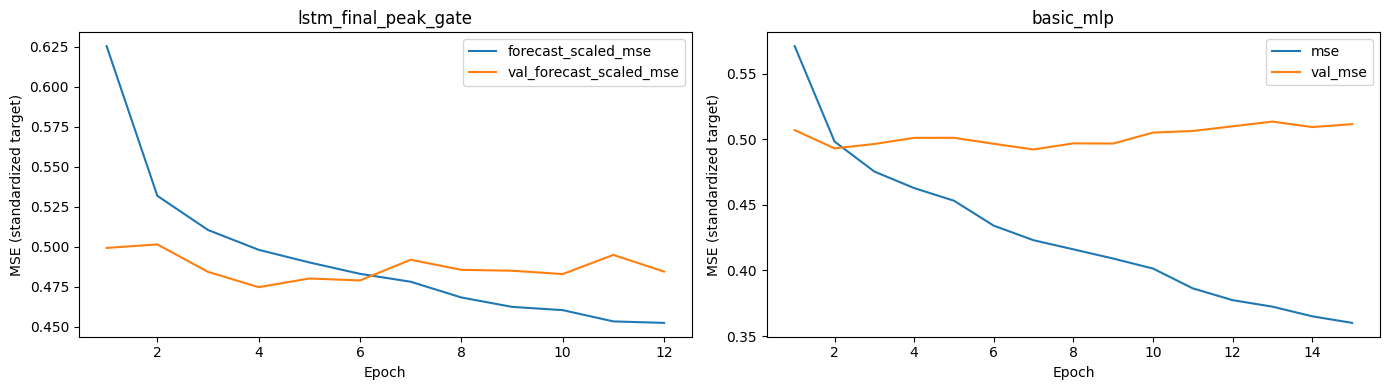

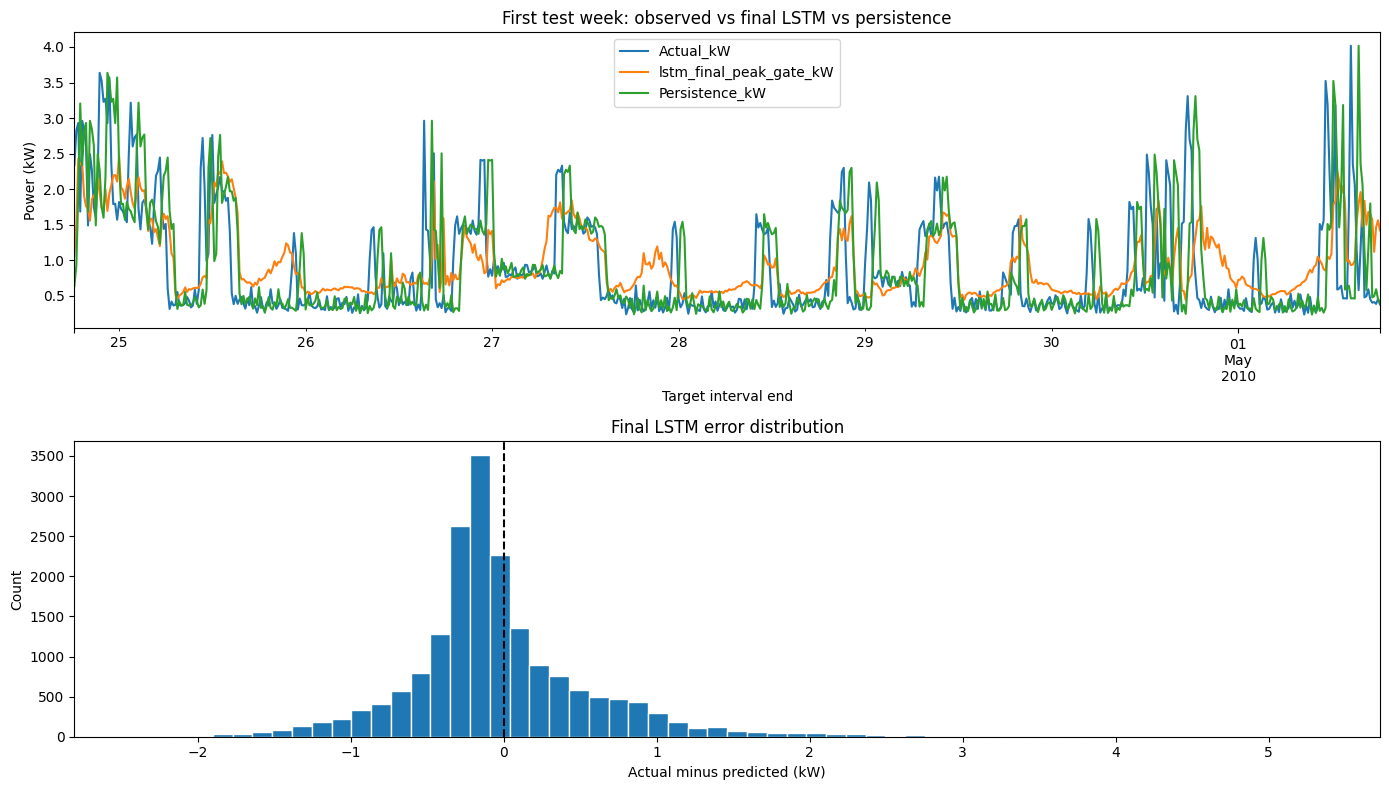

,Segment,Model,Samples,MAE_kW,MSE_kW2,RMSE_kW,R2
0,All test targets,lstm_final_peak_gate,18703,0.4297,0.3797,0.6162,0.4062
1,All test targets,basic_mlp,18703,0.4264,0.3784,0.6152,0.4082
2,All test targets,Persistence,18703,0.5158,0.6520,0.8074,-0.0196
3,All test targets,Daily seasonal,18703,0.6098,0.8392,0.9161,-0.3124
4,All test targets,Weekly seasonal,18703,0.6439,0.8989,0.9481,-0.4058
5,High demand (above training 90th percentile),lstm_final_peak_gate,953,1.3536,2.5751,1.6047,-4.9129
6,High demand (above training 90th percentile),basic_mlp,953,1.5772,3.1414,1.7724,-6.2132
7,High demand (above training 90th percentile),Persistence,953,1.6168,3.5524,1.8848,-7.1570
8,High demand (above training 90th percentile),Daily seasonal,953,1.7852,4.2729,2.0671,-8.8114
9,High demand (above training 90th percentile),Weekly seasonal,953,1.8404,4.5011,2.1216,-9.3354


High-demand threshold from training: 2.503 kW


,Metric,V2,Final,Change_Final_minus_V2
0,MAE_kW,0.4131,0.4297,0.0166
1,RMSE_kW,0.6107,0.6162,0.0055
2,R2,0.4143,0.4062,-0.0081
3,High_demand_MAE_kW,1.4724,1.3536,-0.1188
4,High_demand_RMSE_kW,1.6916,1.6047,-0.0869
5,High_demand_R2,-5.5830,-4.9129,0.6701


In [10]:
# ============================================================
# LEARNING CURVES
# ============================================================

selected_history = histories[
    selected_lstm_name
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4)
)


# Selected LSTM
if (
    "val_forecast_scaled_mse"
    in selected_history.columns
):

    selected_history[
        [
            "forecast_scaled_mse",
            "val_forecast_scaled_mse",
        ]
    ].plot(
        ax=axes[0]
    )

else:

    selected_history[
        [
            "mse",
            "val_mse",
        ]
    ].plot(
        ax=axes[0]
    )


axes[0].set(
    title=selected_lstm_name,
    xlabel="Epoch",
    ylabel="MSE (standardized target)"
)


# Basic MLP
histories[
    "basic_mlp"
][
    [
        "mse",
        "val_mse",
    ]
].plot(
    ax=axes[1]
)

axes[1].set(
    title="basic_mlp",
    xlabel="Epoch",
    ylabel="MSE (standardized target)"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "learning_curves.png",
    dpi=150
)

plt.show()


# ============================================================
# SAVE TEST PREDICTIONS
# ============================================================

prediction_frame = pd.DataFrame({
    "Forecast_origin":
        power.index[
            test_indices
            - HORIZON
        ],

    "Target_interval_end":
        power.index[
            test_indices
        ],

    "Actual_kW":
        actual_test,

    **{
        f"{name}_kW":
            values

        for name, values
        in test_predictions.items()
    },
})


prediction_frame[
    "LSTM_residual_kW"
] = (
    actual_test
    - test_predictions[
        selected_lstm_name
    ]
)


if selected_test_peak_probability is not None:

    prediction_frame[
        "Peak_probability"
    ] = (
        selected_test_peak_probability
    )


prediction_frame.to_csv(
    OUTPUT_DIR
    / "test_predictions.csv",
    index=False
)


# ============================================================
# FIRST TEST WEEK + RESIDUAL HISTOGRAM
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8)
)


plotted = prediction_frame.set_index(
    "Target_interval_end"
)

first_time = plotted.index[0]

view = plotted.loc[
    :
    first_time
    + pd.Timedelta(
        days=7
    )
].reindex(
    pd.date_range(
        first_time,
        first_time
        + pd.Timedelta(
            days=7
        ),
        freq="15min"
    )
)


view[
    [
        "Actual_kW",
        f"{selected_lstm_name}_kW",
        "Persistence_kW",
    ]
].plot(
    ax=axes[0]
)


axes[0].set(
    title=(
        "First test week: "
        "observed vs final LSTM vs persistence"
    ),
    ylabel="Power (kW)",
    xlabel="Target interval end",
)


axes[1].hist(
    prediction_frame[
        "LSTM_residual_kW"
    ],
    bins=60,
    edgecolor="white"
)

axes[1].axvline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set(
    title="Final LSTM error distribution",
    xlabel="Actual minus predicted (kW)",
    ylabel="Count",
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "forecast_and_residuals.png",
    dpi=150
)

plt.show()


# ============================================================
# DEMAND-SEGMENT METRICS
# ============================================================

error_records = []

segment_masks = {
    "All test targets":
        np.ones(
            len(actual_test),
            dtype=bool
        ),

    "High demand (above training 90th percentile)":
        actual_test
        >= peak_threshold,

    "Other demand":
        actual_test
        < peak_threshold,
}


for segment, mask in segment_masks.items():

    if int(
        mask.sum()
    ) < 2:
        continue

    for name, prediction in test_predictions.items():

        error_records.append({
            "Segment":
                segment,

            "Model":
                name,

            "Samples":
                int(
                    mask.sum()
                ),

            **regression_metrics(
                actual_test[
                    mask
                ],
                prediction[
                    mask
                ]
            ),
        })


error_by_segment = pd.DataFrame(
    error_records
)

error_by_segment.to_csv(
    OUTPUT_DIR
    / "error_by_demand_segment.csv",
    index=False
)

display(
    error_by_segment.round(4)
)

print(
    "High-demand threshold from training:",
    round(
        peak_threshold,
        3
    ),
    "kW"
)


# ============================================================
# EXPLICIT COMPARISON WITH THE USER'S V2 FULL RUN
# ============================================================

V2_REFERENCE = {
    "MAE_kW":
        0.4131,

    "RMSE_kW":
        0.6107,

    "R2":
        0.4143,

    "High_demand_MAE_kW":
        1.4724,

    "High_demand_RMSE_kW":
        1.6916,

    "High_demand_R2":
        -5.5830,
}


selected_test_metrics = (
    test_results
    .set_index(
        "Model"
    )
    .loc[
        selected_lstm_name
    ]
)


selected_peak_test_row = (
    error_by_segment[
        (
            error_by_segment[
                "Segment"
            ]
            ==
            "High demand (above training 90th percentile)"
        )
        &
        (
            error_by_segment[
                "Model"
            ]
            ==
            selected_lstm_name
        )
    ]
    .iloc[0]
)


final_vs_v2 = pd.DataFrame([
    {
        "Metric":
            "MAE_kW",

        "V2":
            V2_REFERENCE[
                "MAE_kW"
            ],

        "Final":
            selected_test_metrics[
                "MAE_kW"
            ],
    },

    {
        "Metric":
            "RMSE_kW",

        "V2":
            V2_REFERENCE[
                "RMSE_kW"
            ],

        "Final":
            selected_test_metrics[
                "RMSE_kW"
            ],
    },

    {
        "Metric":
            "R2",

        "V2":
            V2_REFERENCE[
                "R2"
            ],

        "Final":
            selected_test_metrics[
                "R2"
            ],
    },

    {
        "Metric":
            "High_demand_MAE_kW",

        "V2":
            V2_REFERENCE[
                "High_demand_MAE_kW"
            ],

        "Final":
            selected_peak_test_row[
                "MAE_kW"
            ],
    },

    {
        "Metric":
            "High_demand_RMSE_kW",

        "V2":
            V2_REFERENCE[
                "High_demand_RMSE_kW"
            ],

        "Final":
            selected_peak_test_row[
                "RMSE_kW"
            ],
    },

    {
        "Metric":
            "High_demand_R2",

        "V2":
            V2_REFERENCE[
                "High_demand_R2"
            ],

        "Final":
            selected_peak_test_row[
                "R2"
            ],
    },
])


final_vs_v2[
    "Change_Final_minus_V2"
] = (
    final_vs_v2[
        "Final"
    ]
    - final_vs_v2[
        "V2"
    ]
)


final_vs_v2.to_csv(
    OUTPUT_DIR
    / "final_vs_v2_comparison.csv",
    index=False
)

display(
    final_vs_v2.round(4)
)

## 9. Save the final model and Task 8 handoff

The final artifact folder saves:

- selected final LSTM,
- basic MLP,
- all electrical scalers,
- context scaler,
- final engineered feature names,
- predictions,
- demand-segment metrics,
- V2-vs-final comparison,
- peak-classifier information when available,
- representative examples for Task 8,
- manifest and data audit.

The named `lstm_temporal_features` layer is preserved for Task 8 activation
analysis.

In [11]:
# ============================================================
# SAVE FINAL MODELS
# ============================================================

model.save(
    OUTPUT_DIR
    / "task7_FINAL_lstm.keras"
)

basic_model.save(
    OUTPUT_DIR
    / "task7_basic_mlp.keras"
)


# ============================================================
# SAVE PREPROCESSING
# ============================================================

joblib.dump(
    electrical_scalers,
    OUTPUT_DIR
    / "electrical_scalers.joblib"
)

joblib.dump(
    power_scaler,
    OUTPUT_DIR
    / "power_scaler.joblib"
)

joblib.dump(
    context_scaler,
    OUTPUT_DIR
    / "context_scaler.joblib"
)


# ============================================================
# SAVE PREPARED DATA
# ============================================================

power.to_csv(
    OUTPUT_DIR
    / "electricity_15min_multivariate.csv",
    index_label="Interval_end"
)


np.savez_compressed(
    OUTPUT_DIR
    / "prepared_arrays.npz",

    history_values=
        history_values,

    context_values=
        context_values,

    target_scaled=
        target_scaled,

    peak_labels=
        peak_labels,

    timestamps_ns=
        power.index.asi8,

    train_indices=
        train_indices,

    validation_indices=
        val_indices,

    test_indices=
        test_indices,
)


# ============================================================
# TASK 8 REPRESENTATIVE EXAMPLES
# ============================================================

def evenly_spaced(
    ids,
    cap
):
    return ids[
        np.linspace(
            0,
            len(ids) - 1,
            min(
                cap,
                len(ids)
            ),
            dtype=int
        )
    ]


background_indices = evenly_spaced(
    train_indices,
    128
)

explain_indices = evenly_spaced(
    test_indices,
    256
)


background = inputs_for_indices(
    background_indices
)

explain = inputs_for_indices(
    explain_indices
)


np.savez_compressed(
    OUTPUT_DIR
    / "task8_examples.npz",

    background_history=
        background["history"],

    background_context=
        background["context"],

    background_indices=
        background_indices,

    explain_history=
        explain["history"],

    explain_context=
        explain["context"],

    explain_indices=
        explain_indices,

    explain_actual_kw=
        power[
            "actual_kw"
        ]
        .iloc[
            explain_indices
        ]
        .to_numpy(),

    explain_peak_label=
        peak_labels[
            explain_indices
        ],

    explain_target_timestamps_ns=
        power.index[
            explain_indices
        ].asi8,
)


# ============================================================
# MANIFEST
# ============================================================

run_manifest = {
    "run_id":
        RUN_ID,

    "run_mode":
        RUN_MODE,

    "seed":
        SEED,

    "version":
        "Task 7 FINAL peak-gated multi-task LSTM",

    "extended_search":
        EXTENDED_SEARCH,

    "data_audit":
        data_audit,

    "sequence_length":
        SEQUENCE_LENGTH,

    "horizon_steps":
        HORIZON,

    "interval_minutes":
        15,

    "electrical_features":
        ELECTRICAL_FEATURES,

    "target":
        (
            "mean Global_active_power in interval "
            "ending 1 hour after forecast origin"
        ),

    "units":
        "kW",

    "history_features":
        HISTORY_FEATURES,

    "context_features":
        CONTEXT_FEATURES,

    "peak_quantile":
        PEAK_QUANTILE,

    "peak_threshold_kw":
        peak_threshold,

    "peak_regression_weight":
        PEAK_REGRESSION_WEIGHT,

    "peak_classification_weight":
        PEAK_CLASSIFICATION_WEIGHT,

    "auxiliary_peak_loss_weight":
        AUXILIARY_PEAK_LOSS_WEIGHT,

    "validation_objective_weights": {
        "overall":
            VALIDATION_OVERALL_WEIGHT,

        "peak":
            VALIDATION_PEAK_WEIGHT,
    },

    "split_fractions": [
        TRAIN_FRACTION,
        (
            VALIDATION_END_FRACTION
            - TRAIN_FRACTION
        ),
        (
            1
            - VALIDATION_END_FRACTION
        ),
    ],

    "full_eligible_split_counts":
        full_split_counts,

    "used_split_counts": {
        name:
            len(ids)

        for name, ids
        in split_indices.items()
    },

    "selection":
        selection_record,

    "peak_classifier_test_metrics":
        peak_classifier_test_metrics,

    "prediction_postprocessing":
        "inverse scale then clip negative power to zero",

    "versions": {
        "python":
            platform.python_version(),

        "tensorflow":
            tf.__version__,

        "keras":
            keras.__version__,

        "numpy":
            np.__version__,

        "pandas":
            pd.__version__,

        "scikit_learn":
            sklearn.__version__,
    },
}


(
    OUTPUT_DIR
    / "manifest.json"
).write_text(
    json.dumps(
        run_manifest,
        indent=2
    ),
    encoding="utf-8"
)


(
    OUTPUT_DIR
    / "data_audit.json"
).write_text(
    json.dumps(
        data_audit,
        indent=2
    ),
    encoding="utf-8"
)


# ============================================================
# VALIDATION PREDICTIONS
# ============================================================

validation_prediction_frame = pd.DataFrame({
    "Forecast_origin":
        power.index[
            val_indices
            - HORIZON
        ],

    "Target_interval_end":
        power.index[
            val_indices
        ],

    "Actual_kW":
        actual_val,

    **{
        f"{name}_kW":
            pred

        for name, pred
        in validation_predictions.items()
    },
})


for name, probability in validation_peak_probabilities.items():

    if probability is not None:

        validation_prediction_frame[
            f"{name}_peak_probability"
        ] = probability


validation_prediction_frame.to_csv(
    OUTPUT_DIR
    / "validation_predictions.csv",
    index=False
)


# ============================================================
# SAVE / RELOAD CHECK
# ============================================================

reloaded = keras.models.load_model(
    OUTPUT_DIR
    / "task7_FINAL_lstm.keras"
)


probe_inputs = inputs_for_indices(
    test_indices[:8]
)


original_outputs = model(
    probe_inputs,
    training=False
)

reloaded_outputs = reloaded(
    probe_inputs,
    training=False
)


if isinstance(
    original_outputs,
    dict
):

    for key in original_outputs:

        np.testing.assert_allclose(
            original_outputs[
                key
            ].numpy(),

            reloaded_outputs[
                key
            ].numpy(),

            rtol=1e-5,
            atol=1e-6,
        )

else:

    np.testing.assert_allclose(
        original_outputs.numpy(),
        reloaded_outputs.numpy(),
        rtol=1e-5,
        atol=1e-6,
    )


activation_model = keras.Model(
    reloaded.inputs,
    reloaded.get_layer(
        "lstm_temporal_features"
    ).output
)


input_names = [
    tensor.name.split(":")[0]
    for tensor in reloaded.inputs
]


activations = activation_model(
    [
        probe_inputs[
            name
        ]
        for name in input_names
    ],
    training=False
)


assert (
    activations.shape[1]
    == SEQUENCE_LENGTH
)


print(
    "Save/reload check passed."
)

print(
    "Task 8 temporal activation shape:",
    activations.shape
)


# ============================================================
# ZIP FINAL OUTPUTS
# ============================================================

zip_path = shutil.make_archive(
    str(
        OUTPUT_DIR
    ),
    "zip",
    root_dir=OUTPUT_DIR
)

print(
    "Final artifact archive:",
    zip_path
)

Save/reload check passed.
Task 8 temporal activation shape: (8, 96, 64)
Final artifact archive: /content/task7_FINAL_outputs/full_20261012T061006_195817Z.zip


## 10. Final result interpretation

At the end, report the generated numbers exactly.

The final questions are:

1. Did overall RMSE fall below the V2 value of **0.6107 kW**?
2. Did R² improve beyond **0.4143**?
3. Did high-demand RMSE fall below **1.6916 kW**?
4. Was the final peak-gated model actually selected by validation?
5. Does the selected LSTM still beat the MLP and persistence baseline?

Do not claim a gain unless the full-run metrics show it.

In [12]:
lstm_scores = (
    test_results
    .set_index(
        "Model"
    )
    .loc[
        selected_lstm_name
    ]
)


basic_scores = (
    test_results
    .set_index(
        "Model"
    )
    .loc[
        "basic_mlp"
    ]
)


peak_rows = error_by_segment[
    (
        error_by_segment[
            "Segment"
        ]
        ==
        "High demand (above training 90th percentile)"
    )
    &
    (
        error_by_segment[
            "Model"
        ]
        ==
        selected_lstm_name
    )
]


print(
    "TASK 7 FINAL RESULT"
    if RUN_MODE == "full"
    else
    "SMOKE TEST RESULT — NOT FOR SUBMISSION"
)


print(
    "Selected LSTM:",
    selected_lstm_name
)


print(
    f"Test MAE: "
    f"{lstm_scores['MAE_kW']:.4f} kW; "
    f"RMSE: "
    f"{lstm_scores['RMSE_kW']:.4f} kW; "
    f"R2: "
    f"{lstm_scores['R2']:.4f}"
)


if not peak_rows.empty:

    peak_row = peak_rows.iloc[0]

    print(
        f"High-demand MAE: "
        f"{peak_row['MAE_kW']:.4f} kW; "
        f"High-demand RMSE: "
        f"{peak_row['RMSE_kW']:.4f} kW; "
        f"High-demand R2: "
        f"{peak_row['R2']:.4f}"
    )


if peak_classifier_test_metrics is not None:

    print(
        "Peak classifier — "
        f"AUC: "
        f"{peak_classifier_test_metrics['AUC']:.4f}; "
        f"Precision: "
        f"{peak_classifier_test_metrics['Precision']:.4f}; "
        f"Recall: "
        f"{peak_classifier_test_metrics['Recall']:.4f}; "
        f"F1: "
        f"{peak_classifier_test_metrics['F1']:.4f}"
    )


print(
    "LSTM beats basic MLP on test RMSE:",
    bool(
        lstm_scores[
            "RMSE_kW"
        ]
        <
        basic_scores[
            "RMSE_kW"
        ]
    )
)


print(
    "LSTM beats persistence on test RMSE:",
    bool(
        lstm_scores[
            "RMSE_kW"
        ]
        <
        persistence_rmse
    )
)


print(
    "\nREFERENCE V2:"
)

print(
    "MAE 0.4131 kW | "
    "RMSE 0.6107 kW | "
    "R2 0.4143 | "
    "High-demand RMSE 1.6916 kW"
)


print(
    "\nFINAL minus V2 changes:"
)

display(
    final_vs_v2.round(4)
)


print(
    "\nDo not retune from these test results."
)

print(
    "Final Task 8 handoff saved to:",
    OUTPUT_DIR
)

TASK 7 FINAL RESULT
Selected LSTM: lstm_final_peak_gate
Test MAE: 0.4297 kW; RMSE: 0.6162 kW; R2: 0.4062
High-demand MAE: 1.3536 kW; High-demand RMSE: 1.6047 kW; High-demand R2: -4.9129
Peak classifier — AUC: 0.8574; Precision: 0.2926; Recall: 0.3799; F1: 0.3306
LSTM beats basic MLP on test RMSE: False
LSTM beats persistence on test RMSE: True

REFERENCE V2:
MAE 0.4131 kW | RMSE 0.6107 kW | R2 0.4143 | High-demand RMSE 1.6916 kW

FINAL minus V2 changes:


,Metric,V2,Final,Change_Final_minus_V2
0,MAE_kW,0.4131,0.4297,0.0166
1,RMSE_kW,0.6107,0.6162,0.0055
2,R2,0.4143,0.4062,-0.0081
3,High_demand_MAE_kW,1.4724,1.3536,-0.1188
4,High_demand_RMSE_kW,1.6916,1.6047,-0.0869
5,High_demand_R2,-5.5830,-4.9129,0.6701



Do not retune from these test results.
Final Task 8 handoff saved to: /content/task7_FINAL_outputs/full_20261012T061006_195817Z


# Continue here for Task 8
Task 7 must have completed in this runtime. The next cell passes its saved output folder directly to Task 8. No training is performed by Task 8.


In [13]:
task7_result_folder = Path(globals().get('OUTPUT_DIR', ''))
if not (task7_result_folder / 'manifest.json').is_file():
    task7_result_folder = Path(globals().get('TASK7_COMPLETED_OUTPUT_DIR', ''))
if not (task7_result_folder / 'manifest.json').is_file():
    raise RuntimeError('Complete Task 7 above before starting Task 8.')
TASK7_COMPLETED_OUTPUT_DIR = str(task7_result_folder.resolve())
print('Task 8 will use Task 7 results directly:', TASK7_COMPLETED_OUTPUT_DIR)


Task 8 will use Task 7 results directly: /content/task7_FINAL_outputs/full_20261012T061006_195817Z


# Task 8 — Explainable Electricity Forecasting with SHAP
**SHAP explanations, LSTM activation heatmaps, and comparison with the basic neural network.**

This notebook uses the saved outputs of `task7_final_peak_gated_multitask_lstm.py`.
It never trains, tunes, or changes Task 7. The forecast is average power (kW)
in the 15-minute interval ending one hour after the forecast origin.

**Easiest in Colab:** use `task7_and_task8_shap.ipynb`. Run Task 7 there, then
continue to Task 8 in the same notebook. Its saved files are used directly;
no ZIP download or upload is needed. If Task 7 already ran in an active Colab
notebook, these Task 8 cells can also be appended to that notebook.
A separate Colab notebook normally has a separate runtime and cannot see the
other notebook's temporary files. Use a shared saved folder or the combined
notebook. `TASK7_SOURCE` can optionally identify an existing folder or ZIP.
Locally, a single completed run in `task7_FINAL_outputs` is found automatically.
If several runs exist, choose one explicitly. Earlier Task 7 outputs are not
silently substituted for the updated implementation.

Full-test metrics use every saved test prediction. SHAP uses a small, explicitly
reported test sample to limit computation. All reference examples come from
training data. No LIME or separate Integrated Gradients analysis is used.

In [14]:
import importlib.util
import subprocess
import sys

requirements = {
    "tensorflow": "tensorflow>=2.19,<2.21", "shap": "shap>=0.48,<0.51",
    "numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3",
    "matplotlib": "matplotlib>=3.8,<4", "sklearn": "scikit-learn>=1.5,<2",
    "joblib": "joblib>=1.4,<2",
}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

## 1. Settings and helper functions
The defaults explain up to 24 evenly spaced saved test examples plus three
diagnostic cases, using 32 training references. Increase the sample counts for
a broader analysis; doing so increases explanation time, not training time.

SHAP GradientExplainer uses **expected gradients** to approximate SHAP values.
It is a SHAP method related to Integrated Gradients, not an exact enumeration
of feature coalitions. We explain the final non-negative forecast in kW,
including the peak gate when present. The peak score is not an attention layer.
Reference: [SHAP GradientExplainer documentation](https://shap.readthedocs.io/en/stable/generated/shap.GradientExplainer.html).

In [15]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import hashlib
import json
import re
import shutil
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

TASK7_SOURCE = globals().get("TASK7_COMPLETED_OUTPUT_DIR", "")  # Automatic handoff in the combined notebook.
SEED = 42
GLOBAL_EXAMPLES = 24
BACKGROUND_EXAMPLES = 32
SHAP_NSAMPLES = 256
SHAP_MAX_SAMPLES = 1024
SHAP_BATCH_SIZE = 64
ADDITIVITY_ABS_TOL_KW = 0.03
ADDITIVITY_REL_TOL = 0.05
keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_intra_op_parallelism_threads(min(4, os.cpu_count() or 2))
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def resolve_artifacts(source):
    if source:
        candidate = Path(source).expanduser()
    elif Path("task7_artifacts.zip").is_file():
        candidate = Path("task7_artifacts.zip")
    else:
        runs = sorted(p.parent for p in Path("task7_FINAL_outputs").glob("*/manifest.json")
                      if (p.parent / "task7_FINAL_lstm.keras").is_file())
        if len(runs) != 1:
            raise FileNotFoundError(
                f"Found {len(runs)} completed updated Task 7 folders. Set TASK7_SOURCE to your "
                "completed run folder or ZIP, or upload its ZIP as task7_artifacts.zip. "
                "This notebook will not train Task 7 or use old models automatically.")
        candidate = runs[0]
    if not candidate.exists():
        raise FileNotFoundError(f"Task 7 source does not exist: {candidate}")
    if candidate.is_file():
        if not zipfile.is_zipfile(candidate):
            raise ValueError("TASK7_SOURCE must be a Task 7 ZIP or an extracted folder.")
        cache = Path("task8_shap_inputs") / sha256(candidate)[:16]
        cache.mkdir(parents=True, exist_ok=True)
        root = cache.resolve()
        with zipfile.ZipFile(candidate) as archive:
            for entry in archive.infolist():
                # Check Windows and POSIX separators, absolute paths and links.
                normalized = entry.filename.replace("\\", "/")
                if (normalized.startswith("/") or ":" in normalized
                        or not (root / normalized).resolve().is_relative_to(root)
                        or ((entry.external_attr >> 16) & 0o170000) == 0o120000):
                    raise ValueError(f"Unsafe ZIP entry: {entry.filename}")
            archive.extractall(root)
        manifests = list(root.rglob("manifest.json"))
        if len(manifests) != 1:
            raise ValueError("ZIP must contain exactly one completed Task 7 run.")
        candidate = manifests[0].parent
    required = ["manifest.json", "task7_FINAL_lstm.keras", "task7_basic_mlp.keras",
                "power_scaler.joblib", "task8_examples.npz", "test_predictions.csv"]
    absent = [name for name in required if not (candidate / name).is_file()]
    if absent:
        raise FileNotFoundError(f"Incomplete updated Task 7 run; missing: {absent}")
    return candidate.resolve()


def forecast_tensor(outputs):
    if isinstance(outputs, dict):
        return outputs["forecast_scaled"]
    if isinstance(outputs, (tuple, list)):
        raise ValueError("Ambiguous model outputs; expected forecast tensor or named output dictionary.")
    return outputs


def make_forecast_view(network, history_shape, context_shape, mean, scale):
    # A read-only view of existing weights. Fix inference mode to disable dropout.
    history = keras.Input(history_shape, name="explain_history")
    context = keras.Input(context_shape, name="explain_context")
    output = forecast_tensor(network({"history": history, "context": context}, training=False))
    output = keras.layers.Rescaling(scale=scale, offset=mean)(output)
    output = keras.layers.ReLU()(output)  # Same clipping as Task 7 prediction_outputs.
    return keras.Model([history, context], output, name=network.name + "_forecast_kw")


def predict_view(view, inputs, batch_size=128):
    return np.concatenate([np.asarray(view([inputs["history"][i:i + batch_size],
                                           inputs["context"][i:i + batch_size]], training=False)).reshape(-1)
                           for i in range(0, len(inputs["history"]), batch_size)])


def normalize_shap_values(values, inputs):
    # SHAP >=0.45 commonly returns a trailing singleton output dimension.
    if not isinstance(values, list) or len(values) != 2:
        raise ValueError("Expected separate SHAP arrays for history and context.")
    normalized = []
    for value, original in zip(values, inputs):
        value = np.asarray(value)
        if value.shape == original.shape + (1,):
            value = value[..., 0]
        if value.shape != original.shape or not np.isfinite(value).all():
            raise ValueError(f"Unexpected SHAP shape/content: {value.shape}; expected {original.shape}")
        normalized.append(value)
    return normalized


def compute_shap(view, reference, inputs, seed=SEED, nsamples=SHAP_NSAMPLES,
                 max_samples=SHAP_MAX_SAMPLES, batch_size=SHAP_BATCH_SIZE):
    bg = [reference["history"], reference["context"]]
    xx = [inputs["history"], inputs["context"]]
    explainer = shap.GradientExplainer(view, bg, batch_size=batch_size, local_smoothing=0)
    base_value = float(predict_view(view, reference).mean())
    prediction = predict_view(view, inputs)
    started = time.perf_counter()
    phi = normalize_shap_values(explainer.shap_values(xx, nsamples=nsamples, rseed=seed), xx)
    samples_used = np.full(len(prediction), nsamples, dtype=int)
    tolerance = ADDITIVITY_ABS_TOL_KW + ADDITIVITY_REL_TOL * np.abs(prediction - base_value)
    budget = nsamples
    while True:
        summed = phi[0].sum(axis=(1, 2)) + phi[1].sum(axis=1)
        residual = prediction - base_value - summed
        flagged = np.flatnonzero(np.abs(residual) > tolerance)
        if not len(flagged) or budget >= max_samples:
            break
        budget = min(budget * 2, max_samples)
        subset = [array[flagged] for array in xx]
        refined = normalize_shap_values(explainer.shap_values(subset, nsamples=budget, rseed=seed), subset)
        for target, update in zip(phi, refined):
            target[flagged] = update
        samples_used[flagged] = budget
    checks = pd.DataFrame({"Forecast_kW": prediction, "Reference_mean_kW": base_value,
                           "SHAP_sum_kW": summed, "Residual_kW": residual,
                           "Tolerance_kW": tolerance, "Within_tolerance": np.abs(residual) <= tolerance,
                           "Monte_Carlo_samples": samples_used})
    return phi, base_value, checks, time.perf_counter() - started


def regression_scores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    if not len(y):
        return {"Samples": 0, "MAE_kW": np.nan, "RMSE_kW": np.nan, "R2": np.nan}
    return {"Samples": len(y), "MAE_kW": float(mean_absolute_error(y, p)),
            "RMSE_kW": float(np.sqrt(mean_squared_error(y, p))),
            "R2": float(r2_score(y, p)) if len(y) > 1 and np.var(y) > 0 else np.nan}


def choose_cases(y, prediction, threshold):
    order = np.argsort(np.abs(y - prediction), kind="stable")
    high = np.flatnonzero(y >= threshold)
    if len(high):
        peak_index = int(high[np.argmax((y - prediction)[high])])
        peak_label = "Largest high-demand underprediction" if y[peak_index] > prediction[peak_index] else "High-demand example"
    else:
        peak_index, peak_label = int(order[-1]), "Largest error (no high-demand example in pool)"
    return {"Smallest error": int(order[0]), "Median error": int(order[len(order) // 2]), peak_label: peak_index}


def slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def save_figure(name):
    plt.gcf().savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close("all")

## 2. Load and verify the saved run
We check timestamps, test targets, training-reference provenance and prediction
agreement before explaining anything. A compact LSTM remains valid if Task 7
selected it instead of the multitask candidate; its identity is printed below.

In [16]:
ARTIFACT_DIR = resolve_artifacts(TASK7_SOURCE)
manifest = json.loads((ARTIFACT_DIR / "manifest.json").read_text(encoding="utf-8"))
if manifest["run_mode"] != "full":
    raise ValueError("Use a completed full Task 7 run, not smoke-test results.")
SEQUENCE_LENGTH = int(manifest["sequence_length"])
HORIZON = int(manifest["horizon_steps"])
INTERVAL_MINUTES = int(manifest["interval_minutes"])
history_features, context_features = manifest["history_features"], manifest["context_features"]
selected_name = manifest["selection"]["selected_lstm"]
peak_threshold = float(manifest["peak_threshold_kw"])
model_files = {"LSTM": "task7_FINAL_lstm.keras", "Basic neural network": "task7_basic_mlp.keras"}
source_hashes = {filename: sha256(ARTIFACT_DIR / filename) for filename in
                 [*model_files.values(), "manifest.json", "power_scaler.joblib", "task8_examples.npz", "test_predictions.csv"]}
models = {name: keras.models.load_model(ARTIFACT_DIR / filename, compile=False)
          for name, filename in model_files.items()}
scaler = joblib.load(ARTIFACT_DIR / "power_scaler.joblib")
POWER_MEAN, POWER_STD = float(scaler.mean_[0]), float(scaler.scale_[0])
with np.load(ARTIFACT_DIR / "task8_examples.npz", allow_pickle=False) as data:
    examples = {key: data[key] for key in data.files}
X = {key: np.asarray(examples[f"explain_{key}"], dtype=np.float32) for key in ["history", "context"]}
reference_all = {key: np.asarray(examples[f"background_{key}"], dtype=np.float32) for key in X}
actual = np.asarray(examples["explain_actual_kw"]).reshape(-1)
target_times = pd.DatetimeIndex(pd.to_datetime(examples["explain_target_timestamps_ns"]))
assert len(actual) > 0 and X["history"].shape == (len(actual), SEQUENCE_LENGTH, len(history_features))
assert X["context"].shape == (len(actual), len(context_features))
assert len(reference_all["history"]) == len(reference_all["context"]) > 0
assert reference_all["history"].shape[1:] == X["history"].shape[1:]
assert reference_all["context"].shape[1:] == X["context"].shape[1:]
assert all(np.isfinite(a).all() for a in [*X.values(), *reference_all.values(), actual])
assert len(examples["background_indices"]) == len(reference_all["history"])
assert len(examples["explain_indices"]) == len(actual)
assert np.max(examples["background_indices"]) < np.min(examples["explain_indices"])
# The saved prepared arrays establish exact membership in the original split.
arrays_path = ARTIFACT_DIR / "prepared_arrays.npz"
if not arrays_path.is_file():
    raise FileNotFoundError("Keep prepared_arrays.npz in the Task 7 ZIP to verify reference/test membership.")
with np.load(arrays_path, allow_pickle=False) as arrays:
    assert np.isin(examples["background_indices"], arrays["train_indices"]).all()
    assert np.isin(examples["explain_indices"], arrays["test_indices"]).all()
    np.testing.assert_array_equal(examples["explain_target_timestamps_ns"], arrays["timestamps_ns"][examples["explain_indices"]])
saved = pd.read_csv(ARTIFACT_DIR / "test_predictions.csv", parse_dates=["Forecast_origin", "Target_interval_end"])
assert saved["Target_interval_end"].is_unique and saved["Target_interval_end"].is_monotonic_increasing
assert len(saved) == manifest["used_split_counts"]["test"]
assert (saved["Target_interval_end"] - saved["Forecast_origin"]).eq(pd.Timedelta(minutes=HORIZON * INTERVAL_MINUTES)).all()
matched = saved.set_index("Target_interval_end").loc[target_times]
np.testing.assert_allclose(actual, matched["Actual_kW"], atol=1e-6)
views = {name: make_forecast_view(model, X["history"].shape[1:], X["context"].shape[1:], POWER_MEAN, POWER_STD)
         for name, model in models.items()}
columns = {"LSTM": f"{selected_name}_kW", "Basic neural network": "basic_mlp_kW"}
for baseline in ["Persistence", "Daily seasonal", "Weekly seasonal"]:
    if f"{baseline}_kW" in saved:
        columns[baseline] = f"{baseline}_kW"
assert np.isfinite(saved[["Actual_kW", *columns.values()]].to_numpy()).all()
predictions = {name: predict_view(view, X) for name, view in views.items()}
for name, prediction in predictions.items():
    np.testing.assert_allclose(prediction, matched[columns[name]], atol=2e-5, rtol=2e-5)
OUTPUT_DIR = Path("task8_shap_outputs") / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Task 7 run:", manifest["run_id"], "| Selected LSTM:", selected_name)
print(f"Verified {len(actual)} reloaded predictions per neural model; no training performed.")
print(f"High-demand threshold from training: {peak_threshold:.3f} kW")
print("Output folder:", OUTPUT_DIR.resolve())

Task 7 run: 20261012T061006_195817Z | Selected LSTM: lstm_final_peak_gate
Verified 256 reloaded predictions per neural model; no training performed.
High-demand threshold from training: 2.503 kW
Output folder: /content/task8_shap_outputs/run_20261012T061456_970962Z


## 3. Compare performance on the complete test set
MAE is average absolute error. RMSE gives greater weight to large errors.
Lower is better for both; higher R² is better. High-demand rows are selected
using the threshold learned in Task 7's training period. Segment R² can be
negative or undefined and should not be compared directly with overall R².
These tables, rather than the small SHAP sample, establish predictive accuracy.

,Model,Segment,Samples,MAE_kW,RMSE_kW,R2
0,LSTM,All test,18703,0.4297,0.6162,0.4062
1,Basic neural network,All test,18703,0.4264,0.6152,0.4082
2,Persistence,All test,18703,0.5158,0.8074,-0.0196
3,Daily seasonal,All test,18703,0.6098,0.9161,-0.3124
4,Weekly seasonal,All test,18703,0.6439,0.9481,-0.4058
5,LSTM,High demand,953,1.3536,1.6047,-4.9129
6,Basic neural network,High demand,953,1.5772,1.7724,-6.2132
7,Persistence,High demand,953,1.6168,1.8848,-7.1570
8,Daily seasonal,High demand,953,1.7852,2.0671,-8.8114
9,Weekly seasonal,High demand,953,1.8404,2.1216,-9.3354


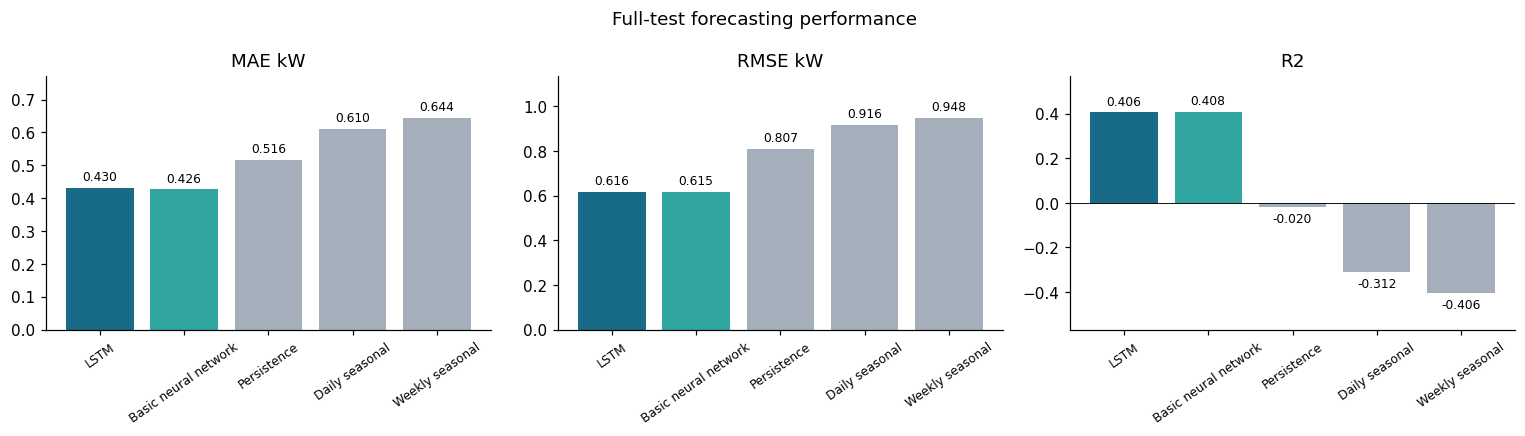

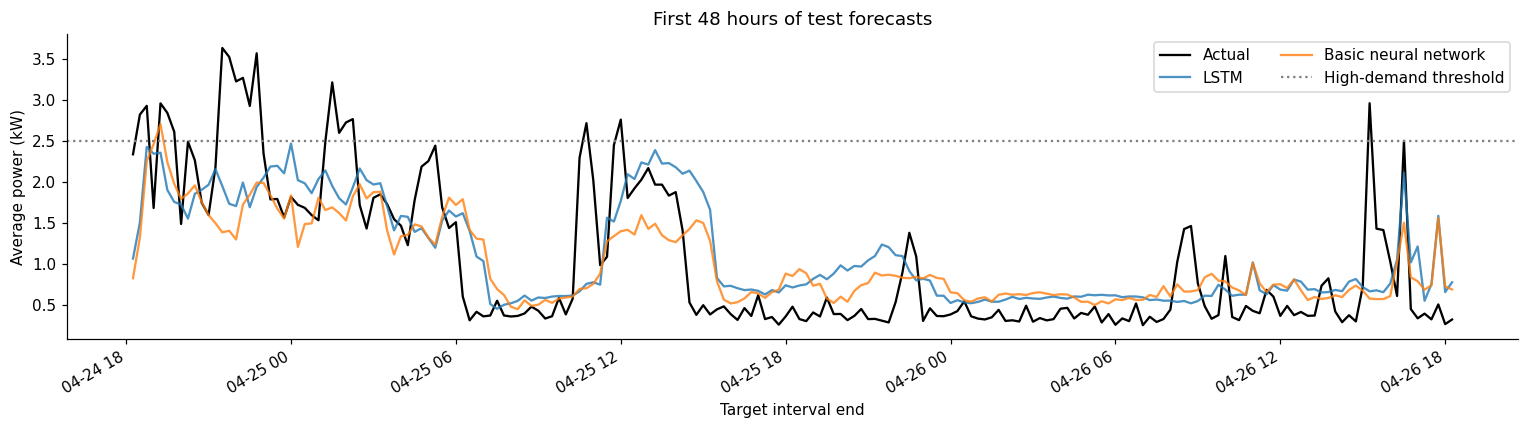

In [17]:
metric_rows = []
for segment, mask in {"All test": np.ones(len(saved), dtype=bool),
                      "High demand": saved["Actual_kW"].to_numpy() >= peak_threshold}.items():
    for name, column in columns.items():
        metric_rows.append({"Model": name, "Segment": segment,
                            **regression_scores(saved.loc[mask, "Actual_kW"], saved.loc[mask, column])})
performance = pd.DataFrame(metric_rows)
performance.to_csv(OUTPUT_DIR / "performance_comparison.csv", index=False)
display(performance.round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
overall = performance[performance["Segment"].eq("All test")].set_index("Model")
for ax, metric in zip(axes, ["MAE_kW", "RMSE_kW", "R2"]):
    bars = ax.bar(overall.index, overall[metric], color=["#176b87", "#31a6a0"] + ["#a5afbc"] * (len(overall) - 2))
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set_title(metric.replace("_", " "))
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.axhline(0, color="black", linewidth=.6)
    ax.margins(y=.2)
fig.suptitle("Full-test forecasting performance")
fig.tight_layout()
save_figure("performance_comparison")
view = saved.set_index("Target_interval_end")
start = view.index[0]
grid = pd.date_range(start, start + pd.Timedelta(days=2), freq=f"{INTERVAL_MINUTES}min")
view = view.reindex(grid)  # Leave gaps visible rather than bridging missing readings.
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(view.index, view["Actual_kW"], color="black", label="Actual", linewidth=1.5)
for name in models:
    ax.plot(view.index, view[columns[name]], label=name, alpha=.8)
ax.axhline(peak_threshold, linestyle=":", color="gray", label="High-demand threshold")
ax.set(title="First 48 hours of test forecasts", ylabel="Average power (kW)", xlabel="Target interval end")
ax.legend(ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
save_figure("actual_vs_predicted")

## 4. Select shared examples and training references
Both neural models use exactly the same reference examples, test examples and
explanation settings. Summary plots use only the evenly spaced sample.
Diagnostic cases deliberately include successes and errors; they do not enter
summary averages unless already selected by the even-spacing rule.

In [18]:
global_positions = np.unique(np.linspace(0, len(actual) - 1, min(GLOBAL_EXAMPLES, len(actual)), dtype=int))
cases = choose_cases(actual, predictions["LSTM"], peak_threshold)
explain_positions = np.unique(np.r_[global_positions, list(cases.values())])
position_to_row = {int(position): row for row, position in enumerate(explain_positions)}
global_rows = np.array([position_to_row[int(position)] for position in global_positions])
bg_positions = np.unique(np.linspace(0, len(reference_all["history"]) - 1,
                                     min(BACKGROUND_EXAMPLES, len(reference_all["history"])), dtype=int))
reference = {key: value[bg_positions] for key, value in reference_all.items()}
explain_inputs = {key: value[explain_positions] for key, value in X.items()}
case_table = pd.DataFrame([{"Case": label, "Example_position": position, "Target_time": target_times[position],
                            "Actual_kW": actual[position],
                            **{name + "_kW": prediction[position] for name, prediction in predictions.items()}}
                           for label, position in cases.items()])
case_table.to_csv(OUTPUT_DIR / "diagnostic_cases.csv", index=False)
display(case_table.round(4))
print(f"SHAP: {len(explain_positions)} examples per model, {len(bg_positions)} training references.")

,Case,Example_position,Target_time,Actual_kW,LSTM_kW,Basic neural network_kW
0,Smallest error,170,2010-09-13 16:15:00,0.4675,0.4696,0.3885
1,Median error,243,2010-11-17 16:45:00,0.8072,0.5143,0.6105
2,Largest high-demand underprediction,65,2010-06-13 10:30:00,4.2264,0.9998,0.9121


SHAP: 26 examples per model, 32 training references.


## 5. Calculate SHAP and check explanation sums
For each example: **reference mean forecast + all SHAP contributions ≈ forecast**.
Values are in kW. Positive contributions raise the forecast relative to the
reference mean; negative contributions lower it. Monte Carlo approximation means
the sum is not exact. Flagged examples are retried with more samples, then any
remaining discrepancy is saved and shown, never redistributed among features.
Passing this check verifies approximate reconstruction, not causal correctness.

In [19]:
explanations, base_values, checks_by_model, elapsed_by_model = {}, {}, {}, {}
for name, view in views.items():
    print(f"Calculating SHAP for {name}...", flush=True)
    phi, base, checks, elapsed = compute_shap(view, reference, explain_inputs)
    checks.insert(0, "Example_position", explain_positions)
    checks.insert(1, "Target_time", target_times[explain_positions])
    checks.insert(0, "Model", name)
    checks.to_csv(OUTPUT_DIR / f"{slug(name)}_shap_checks.csv", index=False)
    np.savez_compressed(OUTPUT_DIR / f"{slug(name)}_shap_values.npz", history=phi[0], context=phi[1],
                        base_value_kw=base, example_positions=explain_positions,
                        task7_target_indices=examples["explain_indices"][explain_positions],
                        reference_target_indices=examples["background_indices"][bg_positions])
    explanations[name], base_values[name], checks_by_model[name], elapsed_by_model[name] = phi, base, checks, elapsed
    print(f"{name}: {checks['Within_tolerance'].sum()}/{len(checks)} sums within tolerance; {elapsed:.1f} seconds.")
checks_all = pd.concat(checks_by_model.values(), ignore_index=True)
checks_all.to_csv(OUTPUT_DIR / "shap_additivity_checks.csv", index=False)
display(checks_all.groupby("Model").agg(Examples=("Within_tolerance", "size"),
                                       Checks_passed=("Within_tolerance", "sum"),
                                       Max_absolute_residual_kW=("Residual_kW", lambda x: x.abs().max())))

Calculating SHAP for LSTM...
LSTM: 25/26 sums within tolerance; 3.6 seconds.
Calculating SHAP for Basic neural network...
Basic neural network: 26/26 sums within tolerance; 1.1 seconds.


,Examples,Checks_passed,Max_absolute_residual_kW
Model,,,
Basic neural network,26,26,0.047845
LSTM,26,25,0.069476


## 6. Which features and past times contribute?
These are summaries of the sampled forecasts, not the whole population.
For each history channel we first sum its signed contributions over time,
then average the absolute totals across examples. This preserves the additive
grouping used in local waterfalls, but opposite effects at different times
can cancel. The time-feature heatmaps separately show mean absolute individual
contributions without that cancellation. Correlated features can share credit.

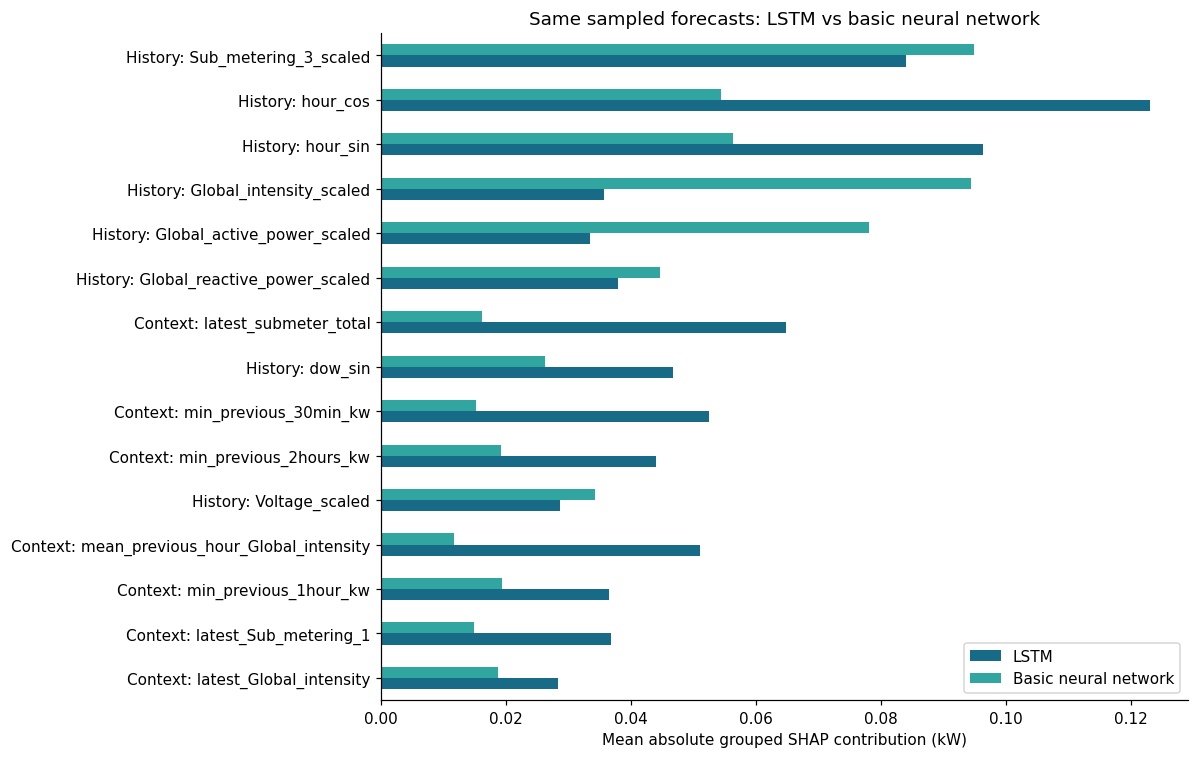

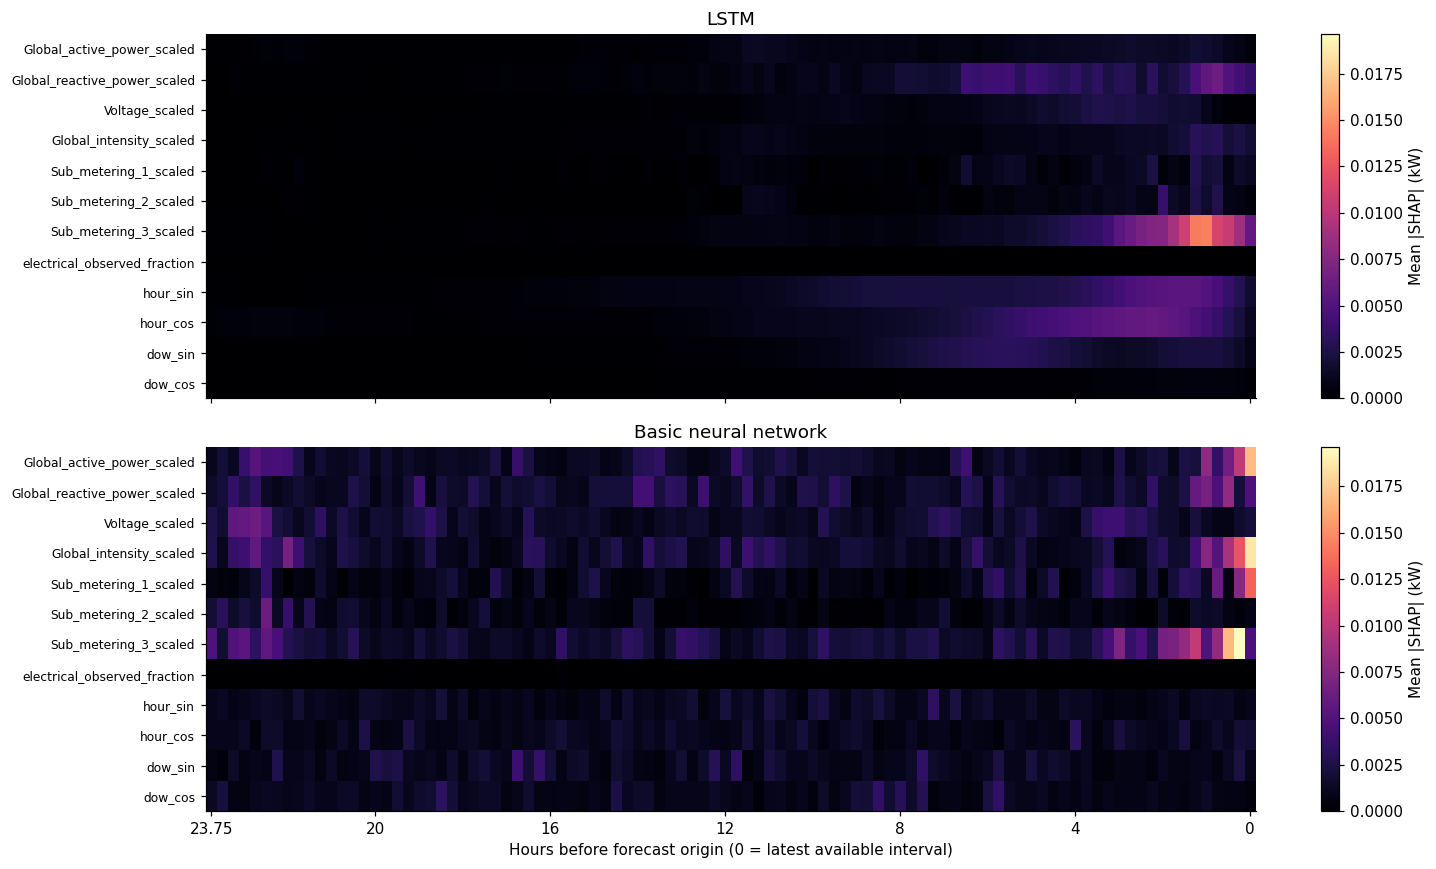

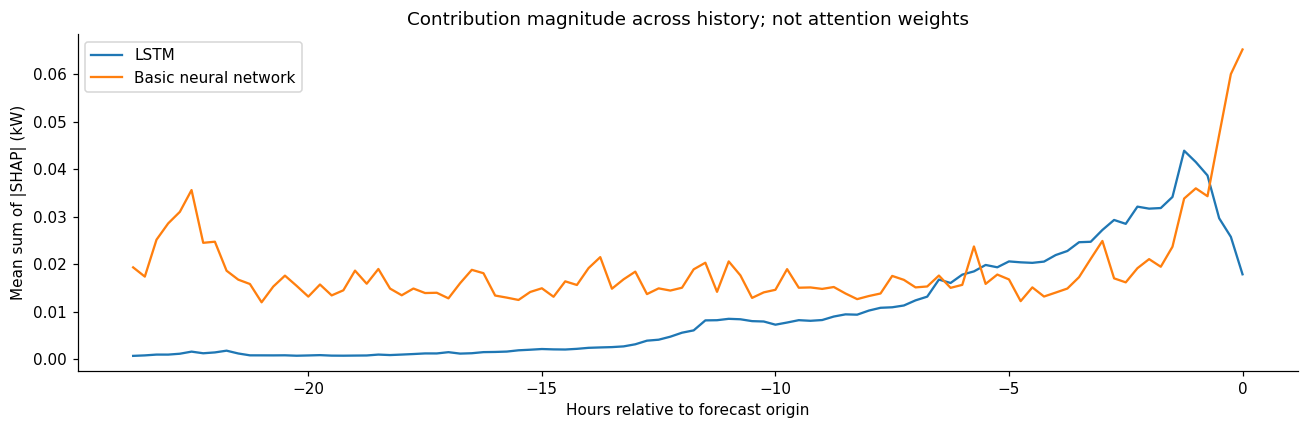

In [20]:
group_names = ["History: " + name for name in history_features] + ["Context: " + name for name in context_features]
grouped = {name: np.concatenate([phi[0].sum(axis=1), phi[1]], axis=1) for name, phi in explanations.items()}
importance = pd.DataFrame({name: np.abs(values[global_rows]).mean(axis=0) for name, values in grouped.items()}, index=group_names)
importance.index.name = "Feature_group"
importance.to_csv(OUTPUT_DIR / "shap_feature_importance.csv")
top_groups = importance.mean(axis=1).nlargest(15).index[::-1]
ax = importance.loc[top_groups].plot.barh(figsize=(11, 7), color=["#176b87", "#31a6a0"])
ax.set(xlabel="Mean absolute grouped SHAP contribution (kW)", ylabel="", title="Same sampled forecasts: LSTM vs basic neural network")
plt.tight_layout()
save_figure("shap_feature_importance")
age_hours = np.arange(SEQUENCE_LENGTH - 1, -1, -1) * INTERVAL_MINUTES / 60
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
common_max = max(float(np.abs(phi[0][global_rows]).mean(axis=0).max()) for phi in explanations.values())
ticks = np.unique(np.linspace(0, SEQUENCE_LENGTH - 1, 7, dtype=int))
for ax, (name, phi) in zip(axes, explanations.items()):
    values = np.abs(phi[0][global_rows]).mean(axis=0).T
    img = ax.imshow(values, aspect="auto", cmap="magma", vmin=0, vmax=common_max or 1)
    ax.set_yticks(np.arange(len(history_features)), history_features, fontsize=8)
    ax.set_title(name)
    fig.colorbar(img, ax=ax, label="Mean |SHAP| (kW)")
axes[-1].set_xticks(ticks, [f"{age_hours[t]:g}" for t in ticks])
axes[-1].set_xlabel("Hours before forecast origin (0 = latest available interval)")
fig.tight_layout()
save_figure("shap_time_feature_heatmaps")
fig, ax = plt.subplots(figsize=(12, 4))
time_importance = {}
for name, phi in explanations.items():
    values = np.abs(phi[0][global_rows]).sum(axis=2).mean(axis=0)
    time_importance[name] = values
    ax.plot(-age_hours, values, label=name)
ax.set(xlabel="Hours relative to forecast origin", ylabel="Mean sum of |SHAP| (kW)", title="Contribution magnitude across history; not attention weights")
ax.legend()
fig.tight_layout()
save_figure("shap_time_importance")
pd.DataFrame({"Hours_before_origin": age_hours, **time_importance}).to_csv(OUTPUT_DIR / "shap_time_importance.csv", index=False)

## 7. Explain individual forecasts
Waterfalls group each history channel across time and keep each context feature
separate. They reconstruct the forecast approximately; titles report the true
forecast and any residual. The plotted SHAP endpoint can differ from it when
Monte Carlo error remains. These explanations describe model behavior, not
physical causes or proven appliance-saving opportunities.

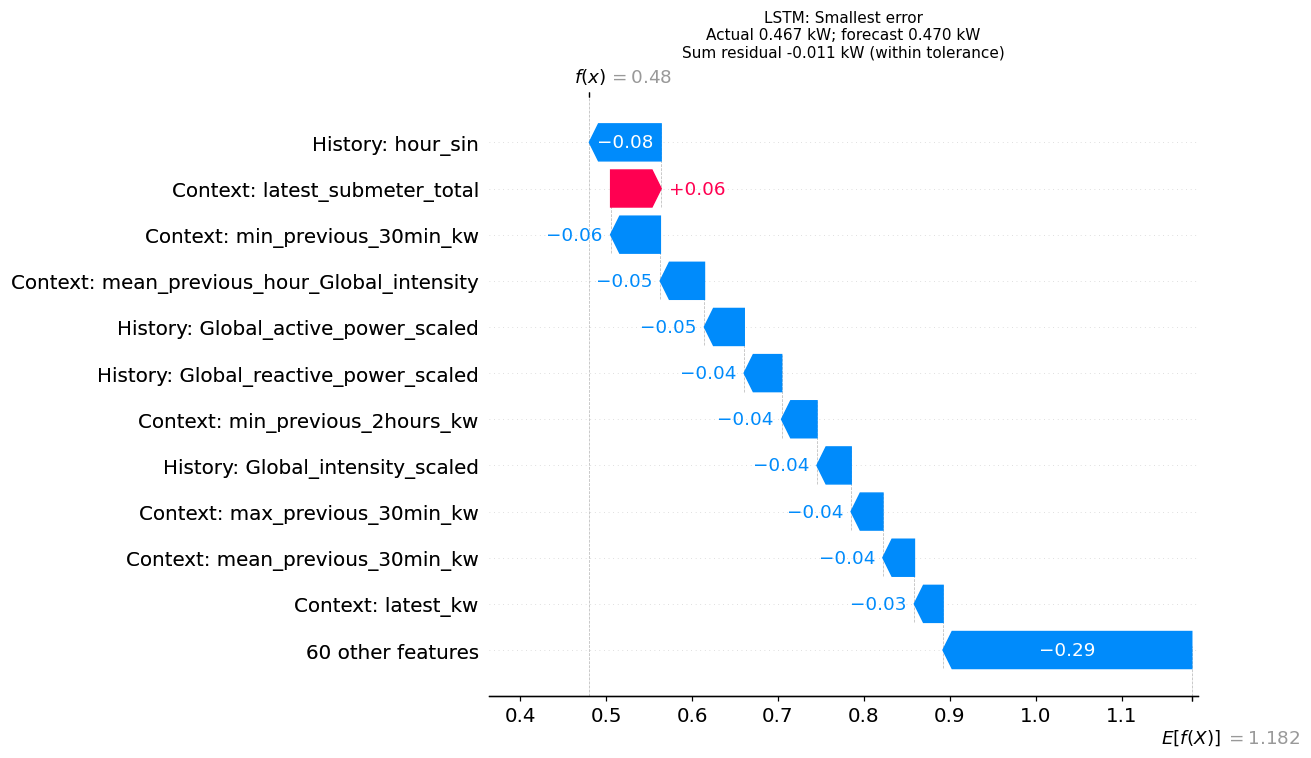

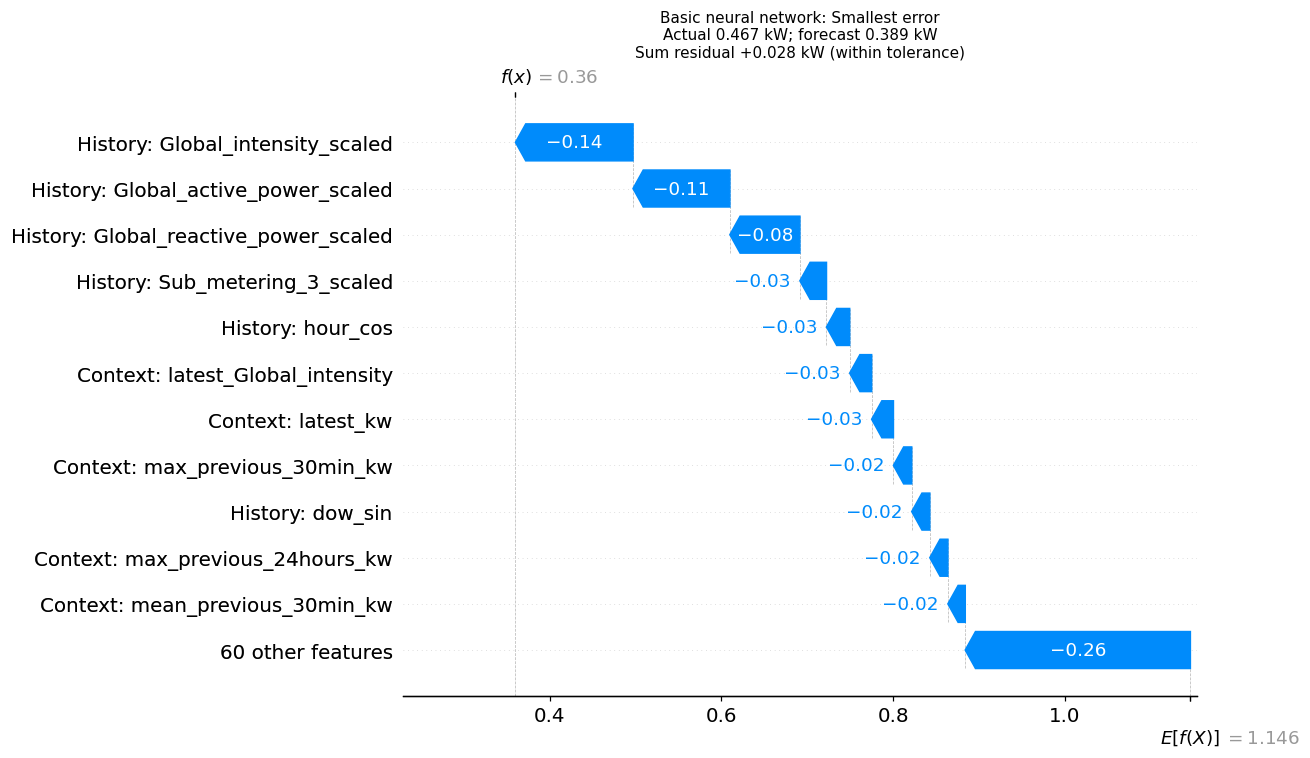

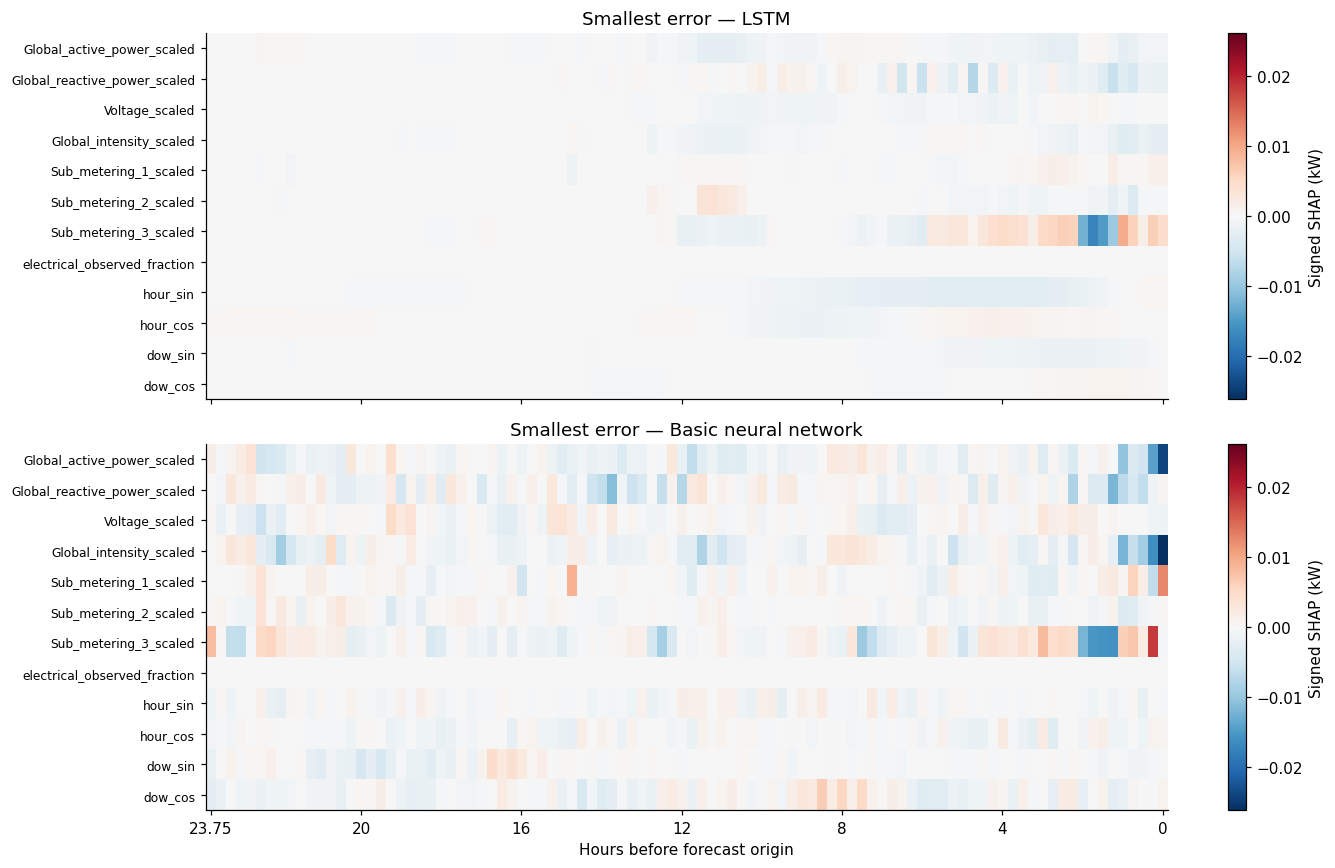

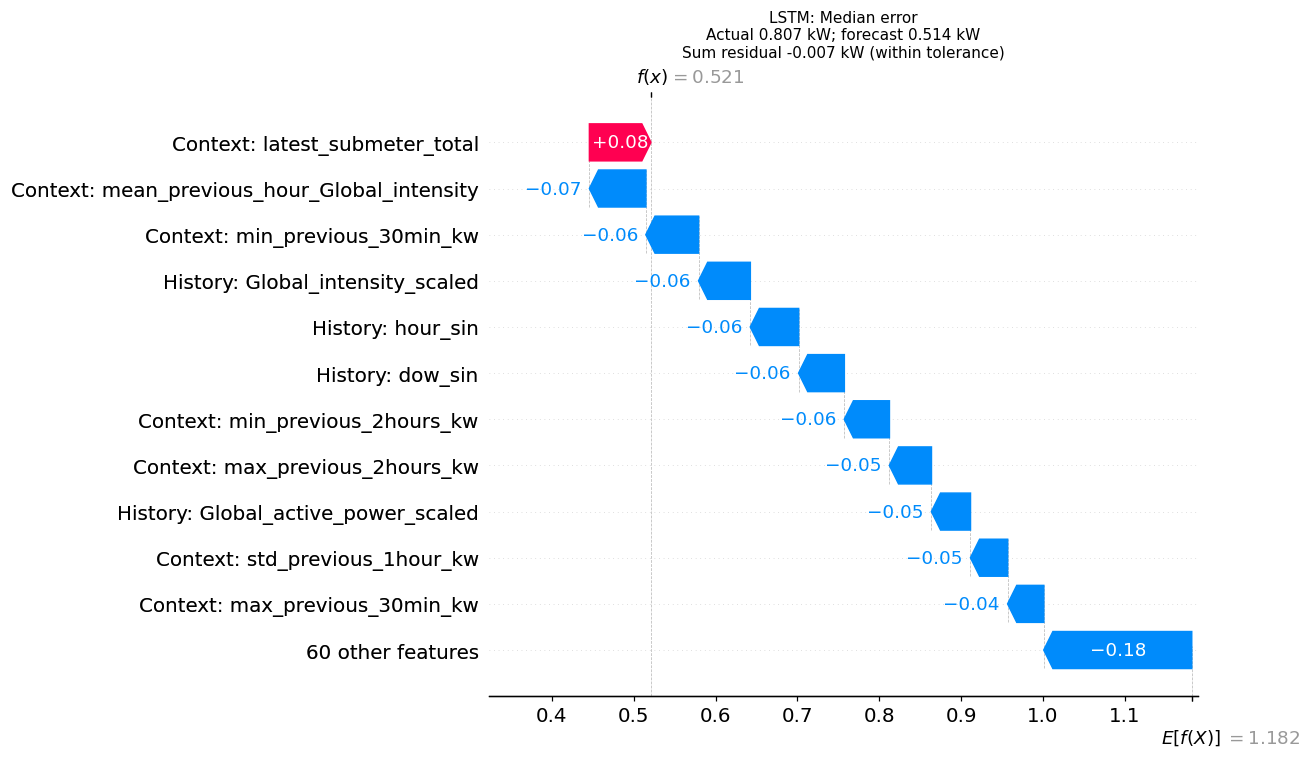

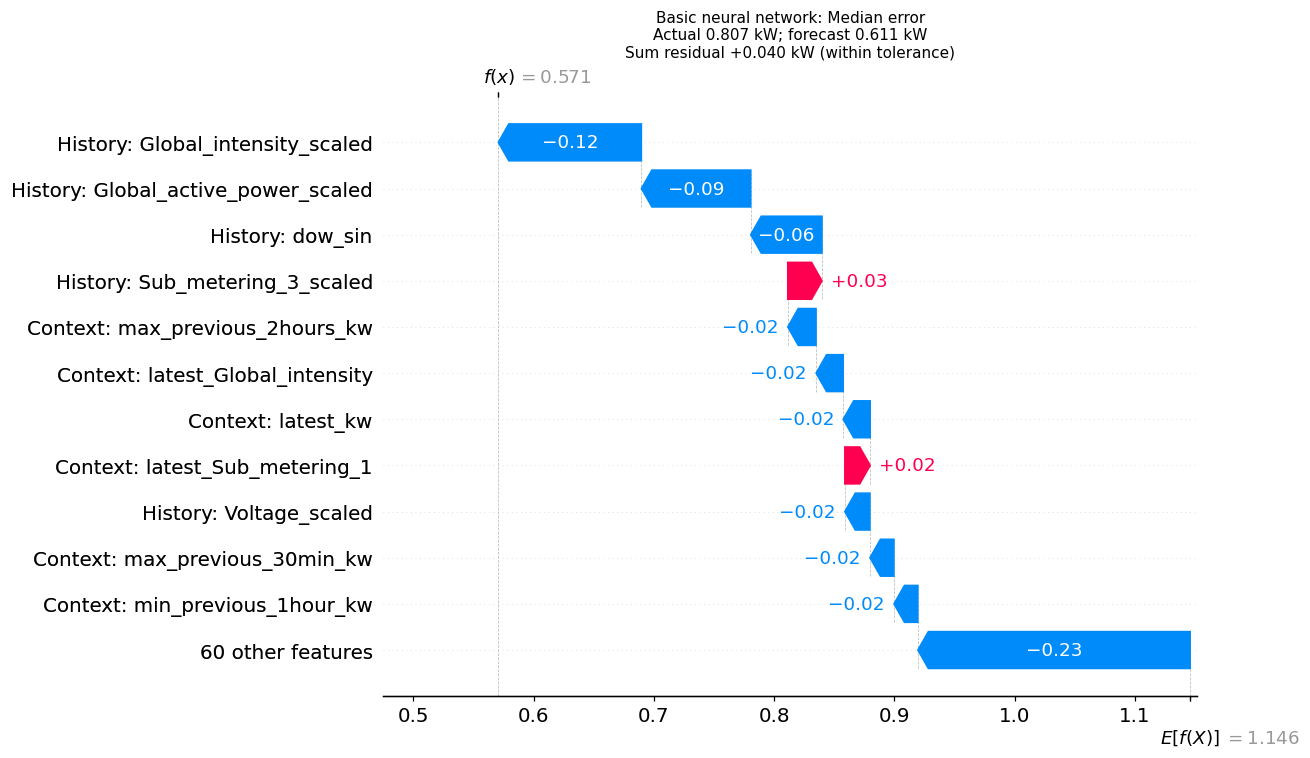

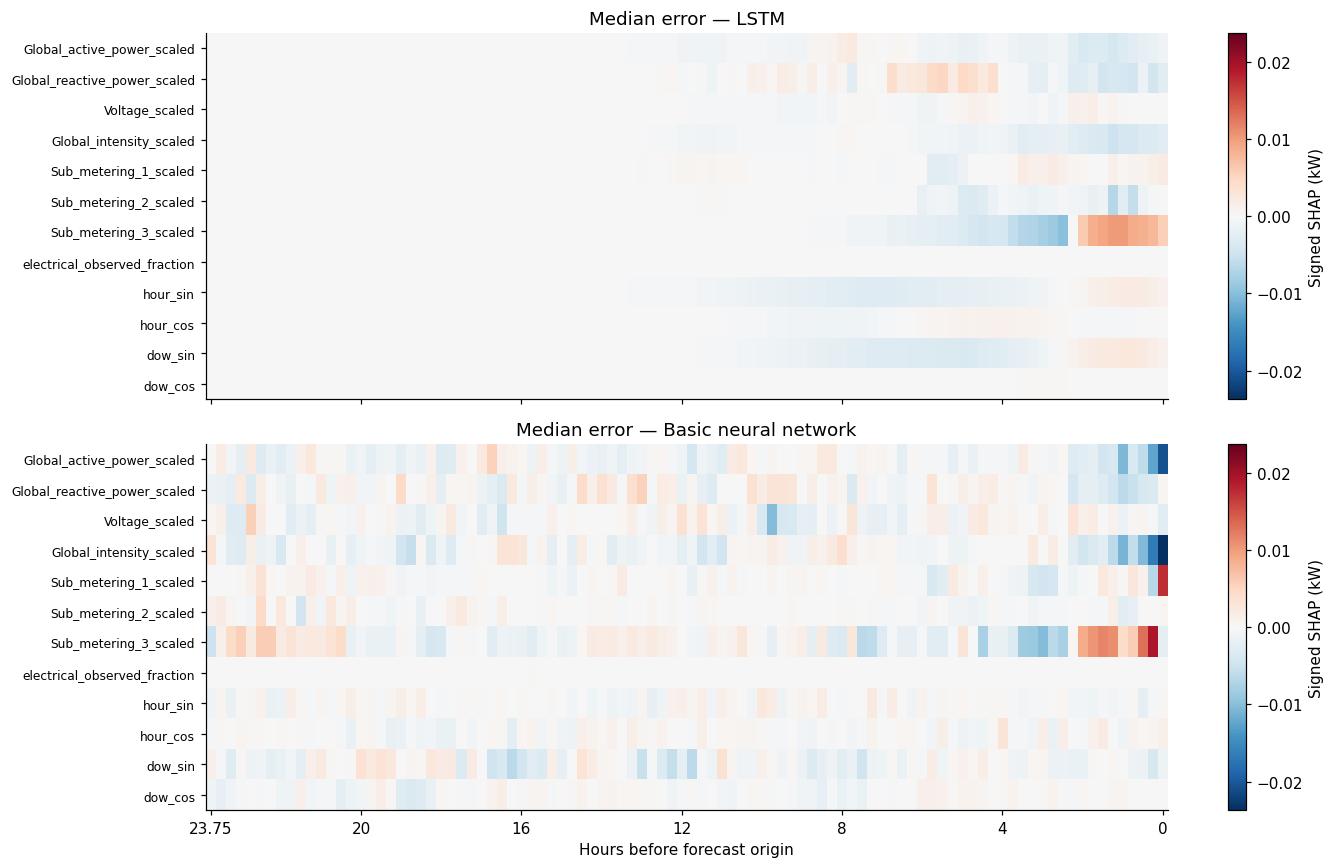

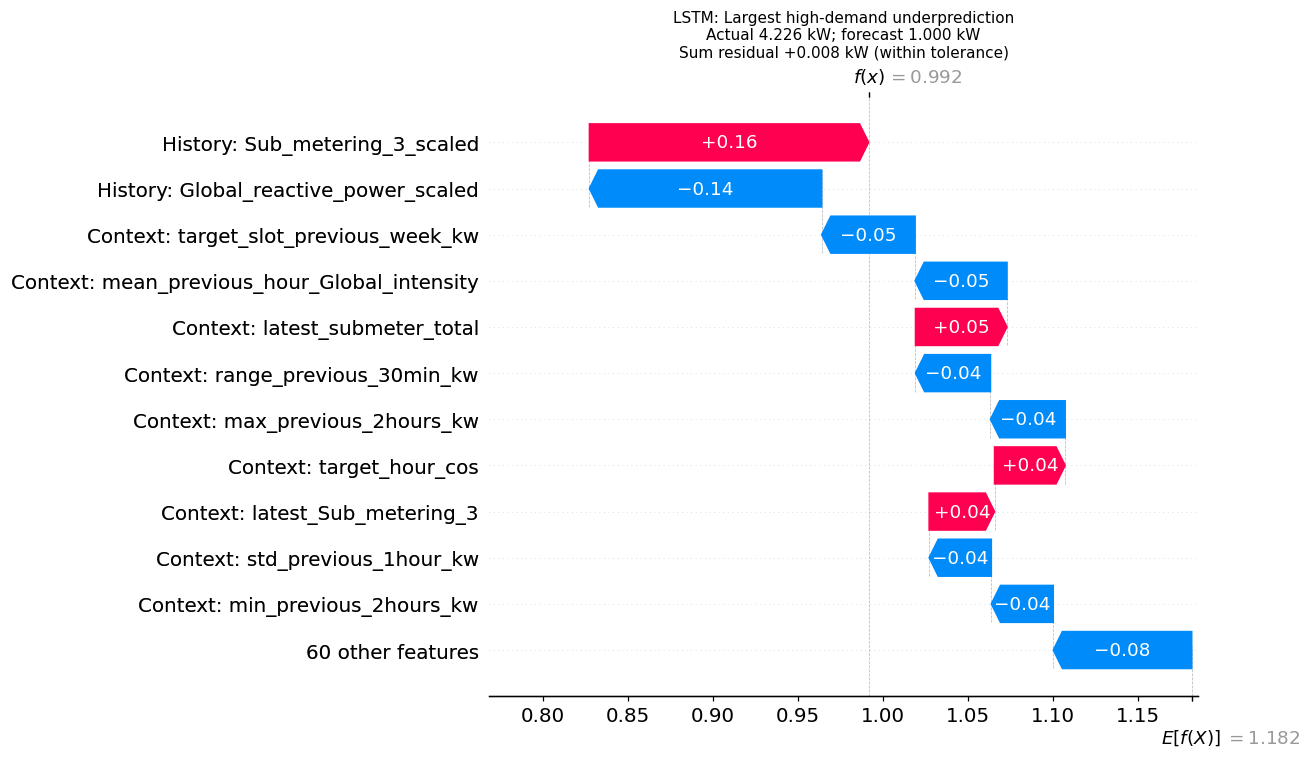

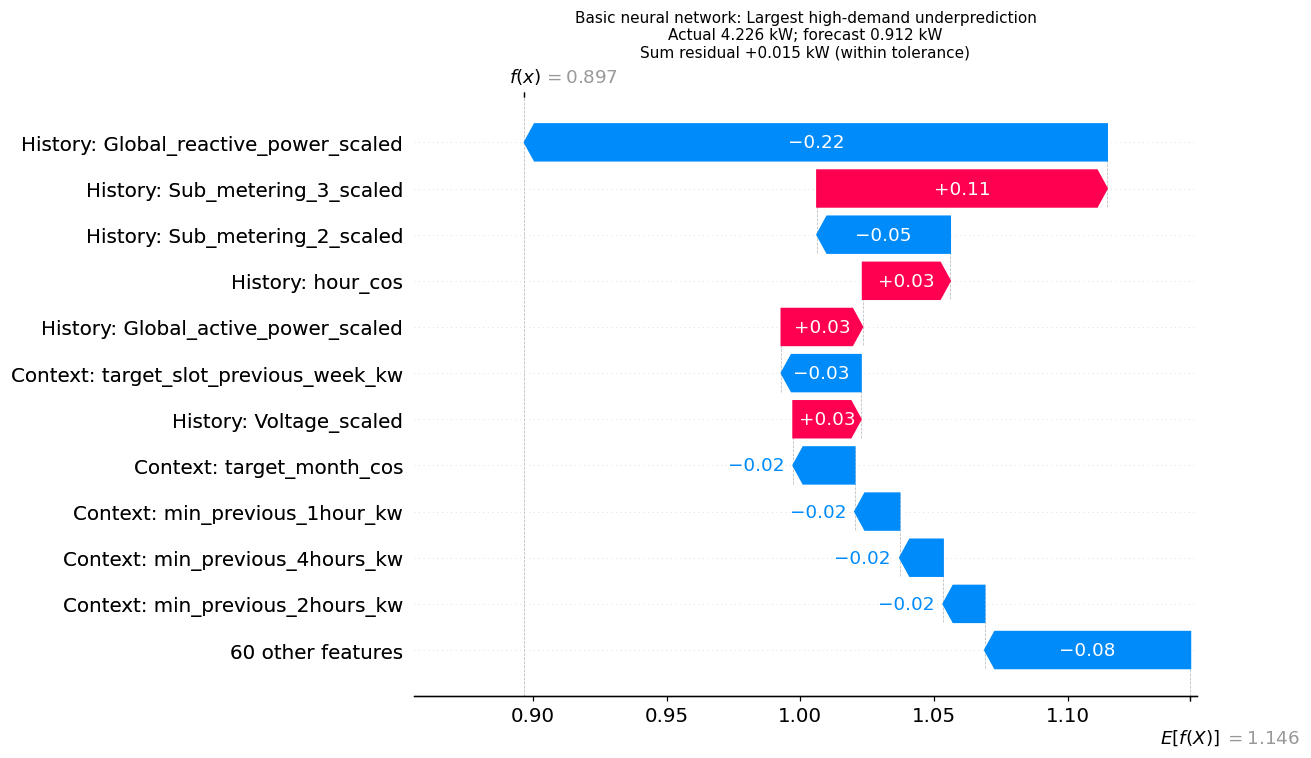

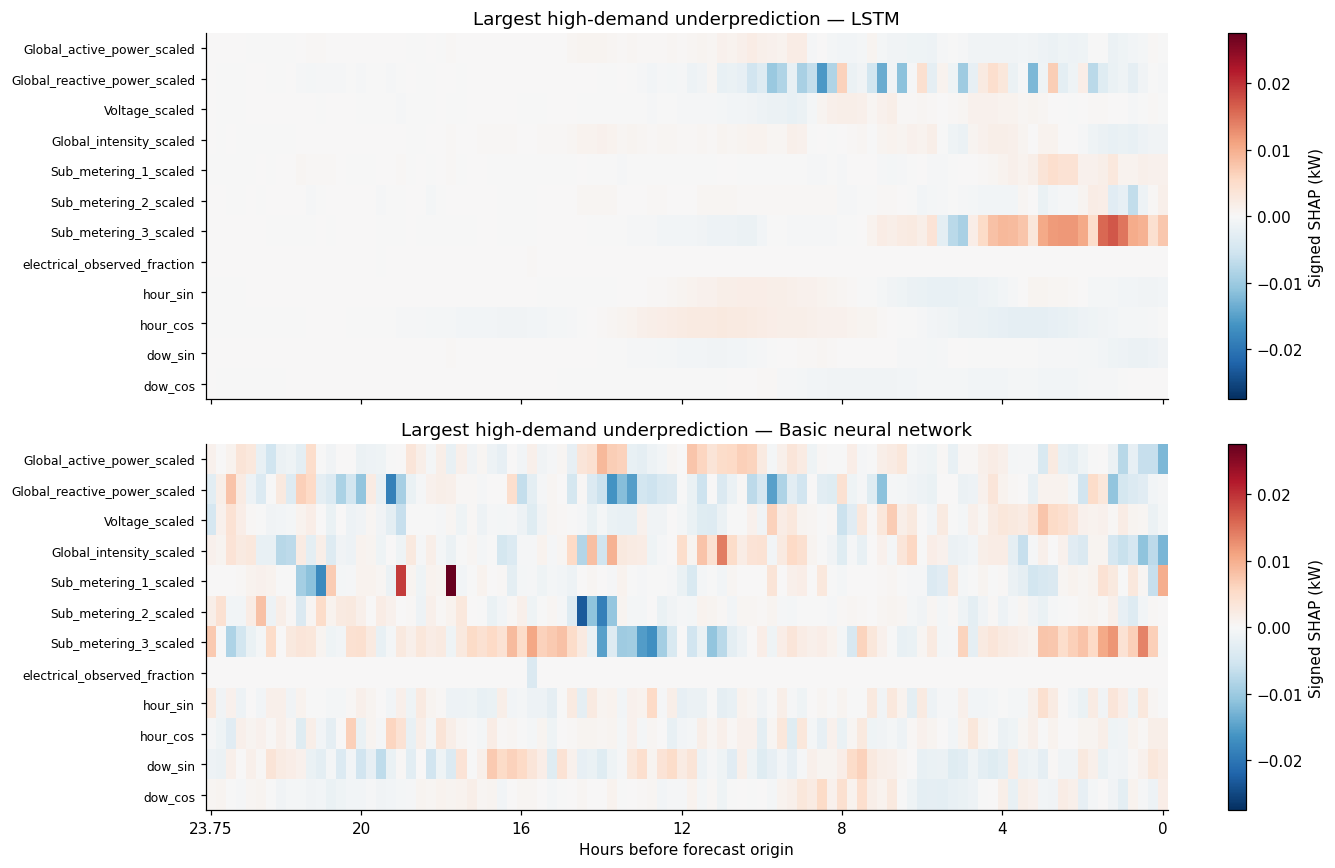

In [21]:
for label, position in cases.items():
    row = position_to_row[position]
    for name in models:
        explanation = shap.Explanation(values=grouped[name][row], base_values=base_values[name], feature_names=group_names)
        shap.plots.waterfall(explanation, max_display=12, show=False)
        check = checks_by_model[name].iloc[row]
        status = "within tolerance" if bool(check["Within_tolerance"]) else "FLAGGED approximation"
        plt.gcf().set_size_inches(12, 7)
        plt.title(f"{name}: {label}\nActual {actual[position]:.3f} kW; forecast {predictions[name][position]:.3f} kW\n"
                  f"Sum residual {check['Residual_kW']:+.3f} kW ({status})", fontsize=10)
        plt.tight_layout()
        save_figure(f"shap_waterfall_{slug(label)}_{slug(name)}")
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    scale = max(float(np.abs(phi[0][row]).max()) for phi in explanations.values()) or 1
    for ax, (name, phi) in zip(axes, explanations.items()):
        img = ax.imshow(phi[0][row].T, aspect="auto", cmap="RdBu_r", vmin=-scale, vmax=scale)
        ax.set_yticks(np.arange(len(history_features)), history_features, fontsize=8)
        ax.set_title(f"{label} — {name}")
        fig.colorbar(img, ax=ax, label="Signed SHAP (kW)")
    axes[-1].set_xticks(ticks, [f"{age_hours[t]:g}" for t in ticks])
    axes[-1].set_xlabel("Hours before forecast origin")
    fig.tight_layout()
    save_figure(f"shap_local_time_heatmap_{slug(label)}")

## 8. LSTM activation heatmaps
Each row is a unit in the first LSTM layer; each column is a history time step.
Color is the unit's hidden-state value, not a SHAP contribution or attention
weight. A strong activation does not by itself prove importance to the forecast.
The basic neural network's dense activations are shown separately: it does not
have a recurrent hidden state evolving across the 96 steps. Unit numbers have
no matching meaning between the two networks, so magnitudes are not ranked
against one another as a measure of interpretability.

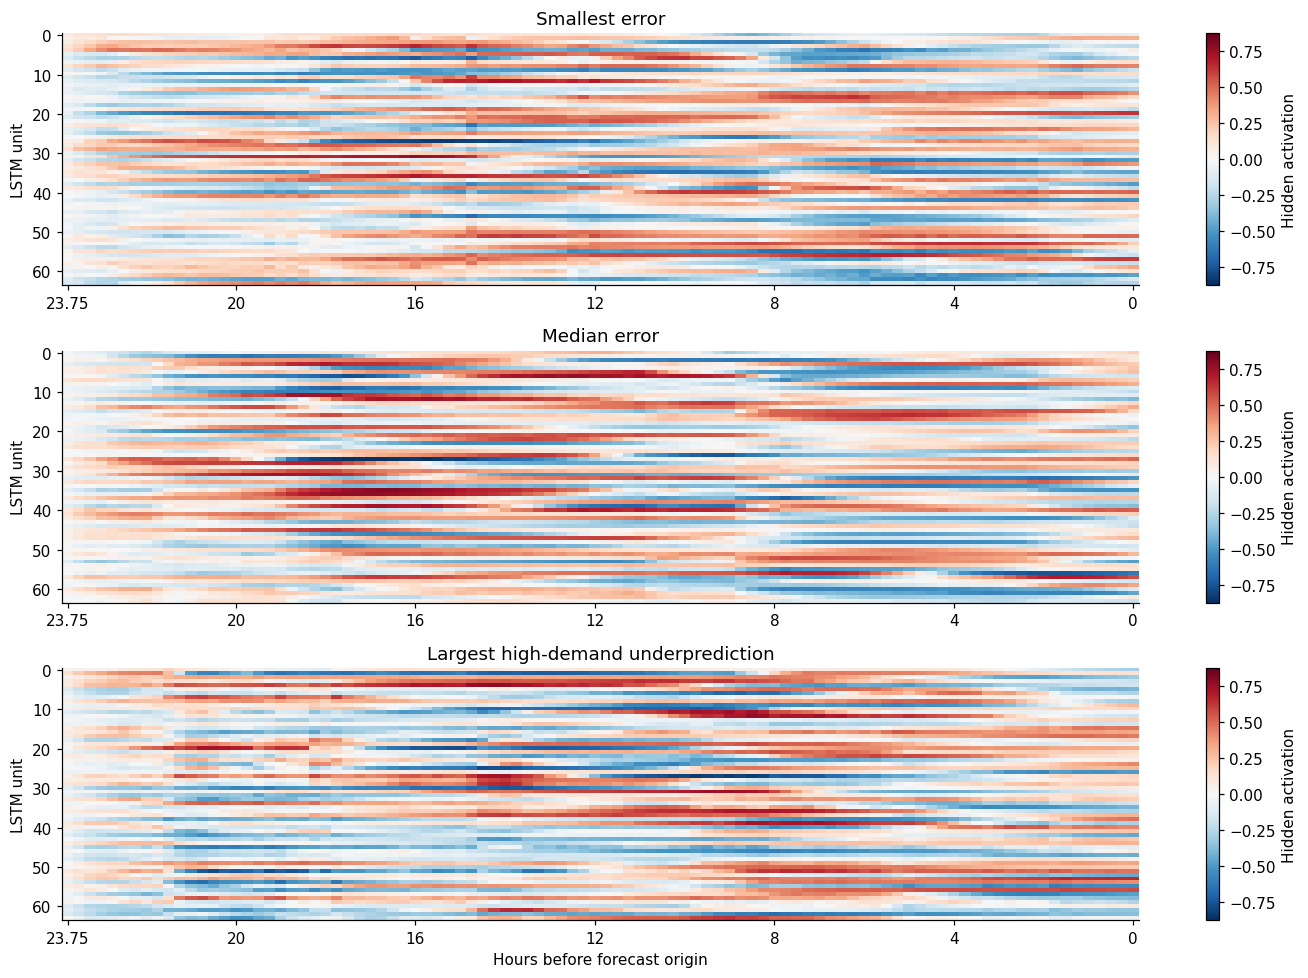

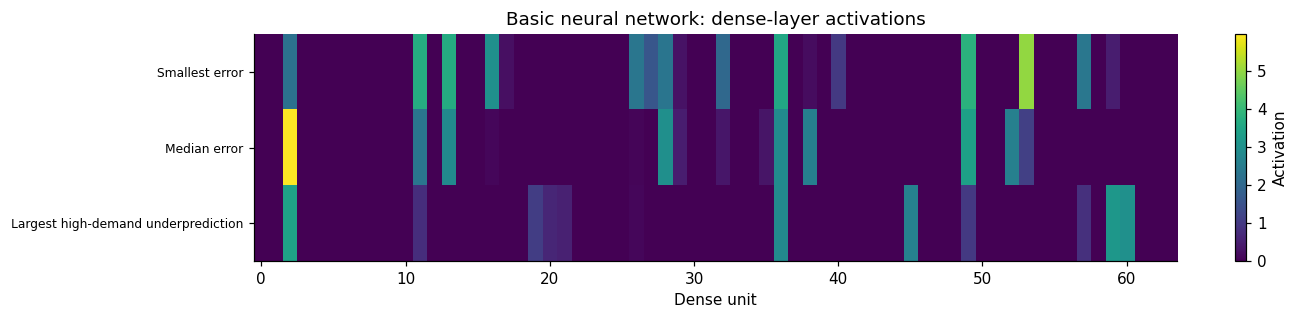

In [22]:
case_positions = list(cases.values())
case_inputs = {key: value[case_positions] for key, value in X.items()}
for name, layer_name in [("LSTM", "lstm_temporal_features"), ("Basic neural network", "dense_features")]:
    network = models[name]
    activation_view = keras.Model(network.inputs, network.get_layer(layer_name).output)
    input_names = [tensor.name.split(":")[0] for tensor in network.inputs]
    activations = np.asarray(activation_view([case_inputs[key] for key in input_names], training=False))
    np.savez_compressed(OUTPUT_DIR / f"{slug(name)}_activations.npz", values=activations,
                        example_positions=case_positions, layer_name=layer_name)
    if name == "LSTM":
        assert activations.shape[1] == SEQUENCE_LENGTH
        fig, axes = plt.subplots(len(cases), 1, figsize=(13, 3 * len(cases)), squeeze=False)
        limit = float(np.abs(activations).max()) or 1
        for ax, (label, _), value in zip(axes[:, 0], cases.items(), activations):
            img = ax.imshow(value.T, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
            ax.set(title=label, ylabel="LSTM unit")
            ax.set_xticks(ticks, [f"{age_hours[t]:g}" for t in ticks])
            fig.colorbar(img, ax=ax, label="Hidden activation")
        axes[-1, 0].set_xlabel("Hours before forecast origin")
    else:
        fig, ax = plt.subplots(figsize=(13, 3))
        img = ax.imshow(activations, aspect="auto", cmap="viridis")
        ax.set_yticks(np.arange(len(cases)), list(cases), fontsize=8)
        ax.set(xlabel="Dense unit", title="Basic neural network: dense-layer activations")
        fig.colorbar(img, ax=ax, label="Activation")
    fig.tight_layout()
    save_figure(f"{slug(name)}_activation_heatmaps")

## 9. Compare interpretability and record limitations
We compare explanation cost, reconstruction checks and prominent input groups.
A smaller SHAP residual or fewer parameters does not establish that one model
is inherently more understandable. SHAP is reference-dependent, correlated
features complicate credit allocation, and interpolated reference/input points
may not correspond to real household states. Sampling also introduces variation.
Neither SHAP nor activations establish causality. No attention mechanism is
claimed. Task 7's existing test performance is reported without retuning.

In [23]:
interpretability_rows = []
for name in models:
    check = checks_by_model[name]
    interpretability_rows.append({"Model": name, "Parameters": models[name].count_params(),
        "Explained_examples": len(explain_positions), "Summary_examples": len(global_positions),
        "Training_references": len(bg_positions), "SHAP_seconds": elapsed_by_model[name],
        "Additivity_checks_passed": int(check["Within_tolerance"].sum()),
        "Flagged_explanations": int((~check["Within_tolerance"]).sum()),
        "Mean_absolute_residual_kW": float(check["Residual_kW"].abs().mean()),
        "Top_sampled_group": importance[name].idxmax(),
        "Internal_visualization": "Temporal LSTM hidden states" if name == "LSTM" else "Dense activations"})
interpretability = pd.DataFrame(interpretability_rows)
interpretability.to_csv(OUTPUT_DIR / "interpretability_comparison.csv", index=False)
display(interpretability)
lstm_rmse, basic_rmse = overall.loc["LSTM", "RMSE_kW"], overall.loc["Basic neural network", "RMSE_kW"]
gain = 100 * (1 - lstm_rmse / basic_rmse) if basic_rmse else np.nan
verdict = "lower" if lstm_rmse < basic_rmse else "higher" if lstm_rmse > basic_rmse else "equal"
flagged_count = int((~checks_all["Within_tolerance"]).sum())
report = f"""# Task 8 — SHAP interpretation and model comparison

Task 7 run: {manifest['run_id']}. Selected LSTM: {selected_name}.
No model training, tuning or weight changes were performed.

## Performance
Full-test LSTM RMSE is {lstm_rmse:.4f} kW; basic neural network RMSE is {basic_rmse:.4f} kW.
The LSTM has {verdict} RMSE; relative improvement versus the basic model is {gain:.2f}%.
See performance_comparison.csv for all-test and high-demand MAE, RMSE, R2 and counts.

## Interpretation
SHAP GradientExplainer explains the clipped power forecast in kW, using the same
{len(bg_positions)} training reference examples for both networks. Summary plots
cover {len(global_positions)} evenly spaced examples from the saved test pool.
Diagnostic cases are chosen separately and do not bias summary averages.
LSTM activations show temporal internal responses; dense activations show the
basic network's responses. Activations are not contribution scores or attention.

{flagged_count} of {len(checks_all)} SHAP reconstructions remain outside the stated
tolerance. Any flagged local explanation requires caution; residuals are not
hidden or assigned to a feature. Reconstruction checks alone do not validate an
explanation's causal meaning, stability or behavior away from these examples.

Both models support feature/time attribution. The LSTM additionally supplies
temporal hidden-state visualizations. Neither model is declared inherently more
interpretable based solely on accuracy, activation intensity or reconstruction.
Prominent sampled groups and explanation costs appear in interpretability_comparison.csv.

## Limits
Expected-gradients SHAP estimates depend on the background and Monte Carlo draws.
Correlated inputs and interpolated, potentially unrealistic household states limit
interpretation. The sample is small, temporal, and from one household dataset;
these are model explanations, not causal appliance-control recommendations.
Results explain the selected Task 7 model, which need not be the peak-gated candidate.
"""
(OUTPUT_DIR / "task8_report.md").write_text(report, encoding="utf-8")
analysis_manifest = {"task7_run_id": manifest["run_id"], "selected_lstm": selected_name,
    "source_folder": str(ARTIFACT_DIR), "source_sha256": source_hashes,
    "method": "SHAP GradientExplainer (expected gradients)", "explained_output": "clipped power forecast in kW",
    "seed": SEED, "background_positions": bg_positions.tolist(), "summary_positions": global_positions.tolist(),
    "explain_positions": explain_positions.tolist(), "diagnostic_cases": cases,
    "nsamples_initial": SHAP_NSAMPLES, "nsamples_max": SHAP_MAX_SAMPLES, "batch_size": SHAP_BATCH_SIZE,
    "additivity_absolute_tolerance_kw": ADDITIVITY_ABS_TOL_KW, "additivity_relative_tolerance": ADDITIVITY_REL_TOL,
    "flagged_explanations": flagged_count, "training_performed": False,
    "versions": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
                 "shap": shap.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
(OUTPUT_DIR / "analysis_manifest.json").write_text(json.dumps(analysis_manifest, indent=2), encoding="utf-8")
for filename, digest in source_hashes.items():
    assert sha256(ARTIFACT_DIR / filename) == digest, f"Source artifact unexpectedly changed: {filename}"
archive_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print(report)
print("Task 8 charts, explanation arrays, checks, tables and report:", OUTPUT_DIR.resolve())
print("Downloadable archive:", Path(archive_path).resolve())

,Model,Parameters,Explained_examples,Summary_examples,Training_references,SHAP_seconds,Additivity_checks_passed,Flagged_explanations,Mean_absolute_residual_kW,Top_sampled_group,Internal_visualization
0,LSTM,40195,26,24,32,3.615883,25,1,0.024334,History: hour_cos,Temporal LSTM hidden states
1,Basic neural network,79681,26,24,32,1.094624,26,0,0.022157,History: Sub_metering_3_scaled,Dense activations


# Task 8 — SHAP interpretation and model comparison

Task 7 run: 20261012T061006_195817Z. Selected LSTM: lstm_final_peak_gate.
No model training, tuning or weight changes were performed.

## Performance
Full-test LSTM RMSE is 0.6162 kW; basic neural network RMSE is 0.6152 kW.
The LSTM has higher RMSE; relative improvement versus the basic model is -0.17%.
See performance_comparison.csv for all-test and high-demand MAE, RMSE, R2 and counts.

## Interpretation
SHAP GradientExplainer explains the clipped power forecast in kW, using the same
32 training reference examples for both networks. Summary plots
cover 24 evenly spaced examples from the saved test pool.
Diagnostic cases are chosen separately and do not bias summary averages.
LSTM activations show temporal internal responses; dense activations show the
basic network's responses. Activations are not contribution scores or attention.

1 of 52 SHAP reconstructions remain outside the stated
tolerance. Any flagged local explanation requi

## Submission checklist
Keep the executed notebook and generated ZIP. Report the actual selected model,
full-test results, SHAP reference choice, sample size and any flagged sums.
Include SHAP feature/time plots, at least one individual explanation, LSTM
activations, and the basic-model comparison. Empty outputs mean the notebook
has not yet been run against your saved Task 7 artifacts.